# CRNN–BiLSTM–CTC từ đầu trên VNLP — Colab
Notebook độc lập, không đọc checkpoint/split/cấu hình LPRNet.

**Chạy theo thứ tự:** cấu hình → giải nén local → metadata/split theo biển → audit crop/hai hàng → xem ảnh → sanity overfit → train → test một lần → phân tích lỗi/inference.

Mục tiêu: đọc toàn chuỗi biển; RGB → crop bbox → tách/ghép hai hàng → letterbox → CNN → 2-layer BiLSTM → CTC. Tất cả trọng số khởi tạo ngẫu nhiên. Đây là CRNN tùy chỉnh, không phải tái hiện nguyên bản paper.

**Giới hạn:** VNLP cung cấp bbox trục thẳng và chuỗi chữ, không cung cấp bốn góc/hàng chữ. Phép tách hàng dựa trên ảnh là heuristic có báo lỗi; không bảo đảm chỉnh phối cảnh hoặc cứu chữ bị mất. Không tự lọc ảnh khó khỏi test. Không hứa accuracy trước khi train.

Tham khảo: [CRNN](https://arxiv.org/abs/1507.05717), [CTCLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CTCLoss.html), [VNLP](https://github.com/fict-labs/VNLP).

In [5]:
# Colab: Runtime > Change runtime type > GPU (T4 trở lên).
%pip -q install opencv-python-headless pandas matplotlib pillow tqdm scikit-learn
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
from pathlib import Path
# Sửa các đường dẫn Drive nếu khác tài khoản của bạn.
ZIP_PATH = Path('/content/drive/MyDrive/Computer Vision/DoAnCuoiKy/Dataset/VNLP_detection.zip')
RUN_DIR = Path('/content/drive/MyDrive/Computer Vision/DoAnCuoiKy/VNLP_CRNN_scratch_v1')
LOCAL_ROOT = Path('/content/vnlp_crnn_data')
SEED = 42
BBOX_MODE = 'xyxy'  # Phải kiểm tra overlay! Thử 'xywh' nếu nguồn của bạn dùng x,y,w,h.
CROP_MARGIN = 0.03
HEIGHT, WIDTH = 32, 256
CHARSET = '0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ'  # Miền ký tự cố định; blank=0.
BATCH_SIZE = 64
NUM_WORKERS = 2
EPOCHS = 80
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 12
USE_AMP = True
RUN_SANITY = True
SANITY_SIZE = 32
SANITY_STEPS = 600
SANITY_MIN_ACC = 0.95
# Sau khi xem overlay, ảnh tách hàng và CSV audit, đổi thành True.
AUDIT_REVIEWED = True
# Bật sau khi đã chốt checkpoint tốt nhất bằng validation. Không dùng test để tune.
RUN_FINAL_TEST = True
RESUME = True
# CSV tùy chọn: image_id,label (sửa nhãn), split_y_frac (khe hai hàng trong crop có margin).
# Không sử dụng nhãn để tìm khe; overrides test chỉ được tạo bởi audit dữ liệu độc lập trước tune.
OVERRIDES_CSV = RUN_DIR / 'manual_overrides.csv'
RUN_DIR.mkdir(parents=True, exist_ok=True)

In [7]:
import os, re, json, math, random, time, hashlib, zipfile, inspect, platform
from collections import Counter
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageEnhance, ImageFilter
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| torch:', torch.__version__)
if DEVICE.type == 'cuda':
    print(torch.cuda.get_device_name(0))
else:
    print('CẢNH BÁO: chưa bật GPU; train đầy đủ trên CPU rất chậm.')
assert ZIP_PATH.is_file(), f'Không tìm thấy {ZIP_PATH}'
PREPROCESS_CONFIG = dict(bbox_mode=BBOX_MODE, margin=CROP_MARGIN, height=HEIGHT,
                         width=WIDTH, two_rows='sloped_gap_v2_flagged_candidate',
                         normalize='RGB [-1,1]', charset=CHARSET)
def json_save(data, path):
    path.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding='utf-8')
json_save(dict(seed=SEED, preprocess=PREPROCESS_CONFIG, batch_size=BATCH_SIZE,
               epochs=EPOCHS, lr=LR, torch=torch.__version__, python=platform.python_version()),
          RUN_DIR / 'config.json')

Device: cuda | torch: 2.11.0+cu130
Tesla T4


## 1. Giải nén vào ổ local Colab
Đọc hàng chục nghìn ảnh trực tiếp trên Drive làm nghẽn I/O. Dữ liệu được giải nén vào /content; checkpoint và kết quả lưu trên Drive. Không xóa thư mục dữ liệu của người dùng.

In [4]:
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as archive:
    members = [m for m in archive.infolist()
               if m.filename.lower().endswith(('.jpg', '.jpeg', '.png'))]
    for member in tqdm(members, desc='Extract local'):
        destination = (LOCAL_ROOT / member.filename).resolve()
        assert destination.is_relative_to(LOCAL_ROOT.resolve()), 'ZIP chứa đường dẫn không an toàn'
        if not destination.exists() or destination.stat().st_size != member.file_size:
            archive.extract(member, LOCAL_ROOT)
paths = sorted(p for p in LOCAL_ROOT.rglob('*')
               if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
assert paths, 'Không tìm thấy ảnh'
print('Images:', len(paths))
display(pd.Series([p.parent.name for p in paths]).value_counts())

Extract local:   0%|          | 0/37297 [00:00<?, ?it/s]

Images: 37297


,count
one_row,19086
two_rows,12618
two_rows_label_xe_may,5593


## 2. Metadata, nhãn và split cố định
Bốn số cuối được diễn giải theo BBOX_MODE và phải xác nhận bằng overlay ở bước tiếp theo.
Chỉ bỏ dấu chấm/gạch nối/khoảng trắng trong nhãn; giữ raw_label và báo lỗi ký tự lạ.
Không tự sửa O/0, I/1 hoặc các tiền tố bất thường.

80/10/10 theo **chuỗi biển đã chuẩn hóa**, stratify layout phổ biến của nhóm nếu đủ nhóm.
File split được tạo một lần; lần sau bắt buộc khớp metadata. Nhãn sửa đổi làm thay đổi nhóm/split phải dùng RUN_DIR mới. Ảnh hỏng/crop sai vẫn nằm trong manifest và được tính sai khi đánh giá.

In [8]:
overrides = {}
if OVERRIDES_CSV.exists():
    ov = pd.read_csv(OVERRIDES_CSV, dtype={'image_id': str, 'label': str}).fillna('')
    assert ov.image_id.is_unique
    overrides = ov.set_index('image_id').to_dict('index')

def normalize_label(raw):
    return re.sub(r'[.\-\s]', '', str(raw).upper())

rows, rejected = [], []
for p in paths:
    image_id = p.relative_to(LOCAL_ROOT).as_posix()
    parts = p.stem.split('_')
    try:
        assert len(parts) >= 8
        raw = parts[-5]
        coords = list(map(int, parts[-4:]))
        label = normalize_label(overrides.get(image_id, {}).get('label') or raw)
        assert label and all(c in CHARSET for c in label), 'nhãn ngoài charset'
        assert 1 <= len(label) <= 16, 'độ dài nhãn bất thường'
        folder = p.parent.name
        assert folder in {'one_row', 'two_rows', 'two_rows_label_xe_may'}, 'folder lạ'
        rows.append(dict(image_id=image_id, path=str(p), raw_label=raw, text=label,
                         layout='one_row' if folder == 'one_row' else 'two_rows',
                         folder=folder, a=coords[0], b=coords[1], c=coords[2], d=coords[3]))
    except Exception as e:
        rejected.append(dict(image_id=image_id, reason=str(e)))
pd.DataFrame(rejected, columns=['image_id','reason']).to_csv(RUN_DIR/'parse_rejected.csv', index=False)
assert not rejected, 'Có tên file/nhãn không đọc được. Xem parse_rejected.csv, sửa trước khi tạo split.'
df = pd.DataFrame(rows)
assert df.image_id.is_unique
assert not (set(overrides) - set(df.image_id)), 'Overrides chứa ID không tồn tại'
df['label_len'] = df.text.str.len()
manifest_identity = df[['image_id','text','layout']].sort_values('image_id')
manifest_hash = hashlib.sha256(manifest_identity.to_csv(index=False).encode()).hexdigest()
split_path = RUN_DIR/'split_manifest.csv'
if split_path.exists():
    saved = pd.read_csv(split_path, dtype=str, keep_default_na=False)
    assert saved.image_id.is_unique
    check = df.merge(saved, on='image_id', how='outer', suffixes=('', '_saved'), indicator=True)
    assert (check['_merge'] == 'both').all(), 'Dữ liệu thay đổi: dùng RUN_DIR mới'
    assert (check.text == check.text_saved).all() and (check.layout == check.layout_saved).all()
    df = df.merge(saved[['image_id','split']], on='image_id', validate='one_to_one')
else:
    groups = df.groupby('text').agg(layout=('layout', lambda s:s.mode().iloc[0])).reset_index()
    strat = groups.layout if groups.layout.value_counts().min() >= 10 else None
    train_g, rest = train_test_split(groups, test_size=.2, random_state=SEED, stratify=strat)
    strat_rest = rest.layout if rest.layout.value_counts().min() >= 2 else None
    val_g, test_g = train_test_split(rest, test_size=.5, random_state=SEED, stratify=strat_rest)
    split_map = {t:s for s,g in [('train',train_g),('val',val_g),('test',test_g)] for t in g.text}
    df['split'] = df.text.map(split_map)
    df[['image_id','text','layout','split']].to_csv(split_path, index=False)
assert set(df.split) == {'train','val','test'}
assert df.groupby('text').split.nunique().max() == 1
SPLIT_HASH = hashlib.sha256(split_path.read_bytes()).hexdigest()
display(pd.crosstab(df.split, df.layout))
display(df.groupby('split').text.nunique().rename('unique_plates'))
display(df.label_len.value_counts().sort_index())
print('Split SHA256:', SPLIT_HASH)

layout,one_row,two_rows
split,,
test,1915,1836
train,15270,14584
val,1901,1791


,unique_plates
split,
test,2095
train,16752
val,2094


,count
label_len,
6,5
7,4221
8,28931
9,4099
10,41


Split SHA256: 1950e981bdee0e3a4cde94d1b5feac8af9b905d6375dec6410a1b9ab06549eb0


## 3. Crop và chuyển hai hàng thành một hàng
Crop không âm thầm ép bbox sai vào một pixel. Nếu tọa độ không hợp lệ hoặc vượt ảnh, mẫu được ghi lỗi.
Margin có thể bị clip tại biên ảnh; bbox gốc phải hợp lệ.

Tìm khe: adaptive threshold trên bản grayscale → tìm đường phân cách trong vùng 30–70% chiều cao, cho phép đường nghiêng → tối thiểu hóa nét mực cắt qua đường → kiểm tra có nét chữ ở cả hai phía. Chấm điểm chỉ dùng vùng giữa ảnh để giảm ảnh hưởng của viền biển.
Khi không tin cậy vẫn giữ ứng viên tốt nhất và gắn cờ low_confidence_candidate, không tự đổi về giữa ảnh. Remap từng cột theo đường phân cách rồi ghép trên trước dưới sau. Phải xem và sửa các ca này; cờ tin cậy chỉ là heuristic, không phải xác suất tách đúng.
Không deskew/warp tự động khi chưa có ước lượng góc tin cậy. Với biển nghiêng mạnh cần nhãn bốn góc/dòng hoặc pipeline bổ sung; notebook này chưa giải quyết hoàn toàn phối cảnh.

Không cắt chặt ký tự bằng contour: giữ chiều rộng cả hàng và mép ngoài để tránh mất chữ. Chuẩn hóa hai hàng cùng chiều cao rồi ghép ngang. Remap này không thay thế homography từ bốn góc.

In [9]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB')).copy()

def bbox_for(row):
    a,b,c,d = (int(row[k]) for k in ['a','b','c','d'])
    return (a,b,c,d) if BBOX_MODE == 'xyxy' else (a,b,a+c,b+d)

def crop_plate(rgb, row):
    h,w = rgb.shape[:2]
    x1,y1,x2,y2 = bbox_for(row)
    if not (0 <= x1 < x2 <= w and 0 <= y1 < y2 <= h):
        raise ValueError(f'bbox ngoài ảnh hoặc rỗng: {(x1,y1,x2,y2)} / {(w,h)}')
    mx,my = round((x2-x1)*CROP_MARGIN), round((y2-y1)*CROP_MARGIN)
    box = (max(0,x1-mx), max(0,y1-my), min(w,x2+mx), min(h,y2+my))
    return rgb[box[1]:box[3],box[0]:box[2]].copy(), box

def row_separator(crop):
    # Tìm một đường phân cách có thể nghiêng; không giả định khe ngang ở h/2.
    h,w = crop.shape[:2]
    if h < 12 or w < 12:
        return np.full(w,h/2,dtype=np.float32), False, 'too_small', np.zeros(h), np.zeros((h,w),np.uint8)
    sh=96; sw=min(256,max(64,round(w*sh/h)))
    gray=cv2.cvtColor(cv2.resize(crop,(sw,sh)),cv2.COLOR_RGB2GRAY)
    gray=cv2.GaussianBlur(gray,(3,3),0)
    mask=cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv2.THRESH_BINARY_INV,31,7)
    ink=(mask>0).astype(np.float32)
    # Bỏ hai mép dọc có viền/ốc vít khi chấm điểm; giữ nguyên ảnh RGB khi OCR.
    xs=np.arange(round(.12*sw),round(.88*sw))
    centers=np.arange(round(.30*sh),round(.70*sh)+1)
    drifts=np.linspace(-.35*sh,.35*sh,15)
    cc,dd=np.meshgrid(centers,drifts,indexing='ij')
    cc=cc.ravel(); dd=dd.ravel()
    ys=cc[:,None]+dd[:,None]*(xs[None,:]/max(1,sw-1)-.5)
    def line_ink(y_values):
        values=[]
        for band in (-1,0,1):
            yy=np.clip(np.rint(y_values+band).astype(int),0,sh-1)
            values.append(ink[yy,xs[None,:]].mean(axis=1))
        return np.mean(values,axis=0)
    gap_ink=line_ink(ys)
    # Nhẹ nhàng ưu tiên vùng giữa và ít nghiêng khi nhiều khe có cùng mức mực.
    scores=gap_ink+.04*np.abs(cc/sh-.5)+.003*np.abs(dd)/(.35*sh)
    best=int(np.argmin(scores))
    # Hai phía của khe phải có nét chữ; độ tin cậy chỉ là heuristic để audit.
    top=max(float(line_ink(ys[best:best+1]-offset*sh)[0]) for offset in (.12,.18,.24))
    bottom=max(float(line_ink(ys[best:best+1]+offset*sh)[0]) for offset in (.12,.18,.24))
    ratio=float(gap_ink[best])/max(1e-6,min(top,bottom))
    ok=min(top,bottom)>.03 and ratio<.65
    cut=(cc[best]+dd[best]*(np.arange(w)/max(1,w-1)-.5))*(h/sh)
    cut=np.clip(cut,2,h-2).astype(np.float32)
    projection=ink.mean(axis=1)
    projection=cv2.resize(projection[:,None],(1,h)).ravel()
    debug_mask=cv2.resize(mask,(w,h),interpolation=cv2.INTER_NEAREST)
    # Không chắc chắn vẫn dùng ứng viên tốt nhất, gắn cờ; không đổi về h//2.
    return cut,bool(ok),('sloped_gap' if ok else 'low_confidence_candidate'),projection,debug_mask

def merge_rows(crop, cut):
    h,w=crop.shape[:2]
    boundary=np.full(w,float(cut),np.float32) if np.ndim(cut)==0 else np.asarray(cut,np.float32)
    if boundary.shape!=(w,) or not np.isfinite(boundary).all() or not ((boundary>1)&(boundary<h-1)).all():
        raise ValueError('Đường phân cách không hợp lệ')
    # Remap từng cột: giữ hai phía đường nghiêng rồi chuẩn hóa chiều cao hàng.
    # Đây không phải phép homography bốn góc; góc nhìn phối cảnh mạnh vẫn cần xử lý riêng.
    xx=np.tile(np.arange(w,dtype=np.float32),(HEIGHT,1))
    t=np.linspace(0,1,HEIGHT,dtype=np.float32)[:,None]
    upper=t*(boundary[None,:]-1)
    lower=boundary[None,:]+t*(h-1-boundary[None,:])
    lines=[]
    for yy,mean_h in ((upper,boundary.mean()),(lower,h-boundary.mean())):
        strip=cv2.remap(crop,xx,yy.astype(np.float32),cv2.INTER_LINEAR,borderMode=cv2.BORDER_REPLICATE)
        new_w=max(1,round(w*HEIGHT/mean_h))
        lines.append(cv2.resize(strip,(new_w,HEIGHT),interpolation=cv2.INTER_LINEAR))
    gap=np.full((HEIGHT,max(2,HEIGHT//8),3),127,np.uint8)
    return np.concatenate([lines[0],gap,lines[1]],axis=1)

def letterbox(line):
    h,w=line.shape[:2]
    scale=min(HEIGHT/h, WIDTH/w)
    nw,nh=max(1,round(w*scale)),max(1,round(h*scale))
    resized=cv2.resize(line,(nw,nh),interpolation=cv2.INTER_AREA if scale<1 else cv2.INTER_LINEAR)
    out=np.full((HEIGHT,WIDTH,3),127,np.uint8)
    y=(HEIGHT-nh)//2
    out[y:y+nh,:nw]=resized
    return out, nw, nh

def preprocess(row, return_debug=False):
    rgb=read_rgb(row['path'])
    crop,box=crop_plate(rgb,row)
    cut=None; ok=True; reason='one_row'; proj=None; mask=None
    line=crop
    if row['layout']=='two_rows':
        cut,ok,reason,proj,mask=row_separator(crop)
        override=overrides.get(row['image_id'],{}).get('split_y_frac','')
        if override != '':
            frac=float(override)
            assert 0.1 < frac < .9
            cut=round(frac*crop.shape[0]); ok=True; reason='manual_override'
        line=merge_rows(crop,cut)
    image,nw,nh=letterbox(line)
    info=dict(split_ok=ok, split_method=reason, split_y=float(np.median(cut)) if cut is not None else None, content_width=nw, content_height=nh,
              crop_width=crop.shape[1],crop_height=crop.shape[0],
              blur=float(cv2.Laplacian(cv2.cvtColor(crop,cv2.COLOR_RGB2GRAY),cv2.CV_64F).var()),
              aspect=float(line.shape[1]/line.shape[0]))
    if return_debug:
        return image,info,dict(original=rgb,crop=crop,line=line,box=box,projection=proj,mask=mask,cut_line=cut)
    return image,info

In [10]:
# Audit toàn bộ: lỗi không bị loại khỏi split; ảnh invalid sẽ được tính là OCR thất bại.
CACHE_DIR=Path('/content/vnlp_crnn_cache')
CACHE_DIR.mkdir(parents=True,exist_ok=True)
audits=[]
for row in tqdm(df.to_dict('records'), desc='Audit crops/layout'):
    try:
        processed,info=preprocess(row)
        cache_path=CACHE_DIR/(hashlib.sha256(row['image_id'].encode()).hexdigest()+'.png')
        assert cv2.imwrite(str(cache_path),cv2.cvtColor(processed,cv2.COLOR_RGB2BGR)), 'Không ghi được cache'
        info['cache_path']=str(cache_path)
        audits.append(dict(image_id=row['image_id'],valid=True,error='',**info))
    except Exception as e:
        audits.append(dict(image_id=row['image_id'],valid=False,error=str(e),
                           split_ok=False,split_method='invalid'))
audit=pd.DataFrame(audits)
df=df.merge(audit,on='image_id',validate='one_to_one')
df['quality_review']=(~df.valid | ~df.split_ok | (df.label_len<7) | (df.label_len>9)
                      | (df.content_height.fillna(0)<20)
                      | (df.crop_height.fillna(0)<16) | (df.blur.fillna(0)<15))
# blur<15 chỉ là cờ để xem, không phải ngưỡng loại dữ liệu.
df.to_csv(RUN_DIR/'metadata_audit.csv',index=False)
display(df.groupby(['split','layout']).agg(samples=('image_id','size'),
        valid_crops=('valid','sum'), confident_split=('split_ok','sum'), review=('quality_review','sum')))
display(df[df.quality_review & (df.split!='test')][
    ['image_id','text','layout','error','split_method','content_height','blur']].head(30))
print('Review CSV:',RUN_DIR/'metadata_audit.csv')
# Exact byte duplicates across split: phát hiện nhãn khác nhau nhưng ảnh giống hệt.
hash_rows=[]
for row in tqdm(df.to_dict('records'), desc='Hash duplicate audit'):
    hash_rows.append((row['image_id'],hashlib.sha256(Path(row['path']).read_bytes()).hexdigest()))
hash_df=pd.DataFrame(hash_rows,columns=['image_id','sha256'])
df=df.merge(hash_df,on='image_id',validate='one_to_one')
cross=df.groupby('sha256').split.nunique()
bad_hash=set(cross[cross>1].index)
df[df.sha256.isin(bad_hash)].to_csv(RUN_DIR/'cross_split_duplicates.csv',index=False)
assert not bad_hash, 'Ảnh byte-identical khác split! Sửa nhãn/nhóm dữ liệu rồi tạo RUN_DIR mới.'
print('Không có ảnh trùng byte xuyên split. Ảnh gần trùng chưa được loại tự động.')

Audit crops/layout:   0%|          | 0/37297 [00:00<?, ?it/s]

samples  valid_crops  confident_split  review
split layout                                                 
test  one_row      1915         1915             1915       0
      two_rows     1836         1836             1824      23
train one_row     15270        15270            15270       3
      two_rows    14584        14584            14525     114
val   one_row      1901         1901             1901       0
      two_rows     1791         1791             1778      18

,image_id,text,layout,error,split_method,content_height,blur
189,detection/one_row/1_1959_1_BC36C26957_61_230_6...,BC36C26957,one_row,,one_row,32,37.665965
13578,detection/one_row/7_2427_1_33H522_75_180_589_2...,33H522,one_row,,one_row,32,193.143414
16833,detection/one_row/8_1663_1_36B02124_49_225_585...,36B02124,one_row,,one_row,32,13.974671
19368,detection/two_rows/1_1299_0_36B1038_390_291_45...,36B1038,two_rows,,low_confidence_candidate,32,613.729268
19388,detection/two_rows/1_1316_0_36B1394_478_257_53...,36B1394,two_rows,,low_confidence_candidate,32,4346.306081
19390,detection/two_rows/1_1318_0_36B1419_105_234_16...,36B1419,two_rows,,low_confidence_candidate,32,2781.057003
19394,detection/two_rows/1_1321_0_36B1426_156_225_22...,36B1426,two_rows,,low_confidence_candidate,32,1656.708062
19395,detection/two_rows/1_1322_0_36B1427_434_233_50...,36B1427,two_rows,,low_confidence_candidate,32,2064.095987
19427,detection/two_rows/1_1353_0_36B1868_108_250_17...,36B1868,two_rows,,low_confidence_candidate,32,1361.316286
19515,detection/two_rows/1_1438_0_36C3998_143_237_21...,36C3998,two_rows,,low_confidence_candidate,32,1336.782889


Review CSV: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/VNLP_CRNN_scratch_v1/metadata_audit.csv


Hash duplicate audit:   0%|          | 0/37297 [00:00<?, ?it/s]

AssertionError: Ảnh byte-identical khác split! Sửa nhãn/nhóm dữ liệu rồi tạo RUN_DIR mới.

In [11]:
# Chạy ngay sau cell báo lỗi cross_split_duplicates.
import hashlib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Không đổi split của một lần train đã có checkpoint.
assert not any(
    (RUN_DIR / name).exists()
    for name in ["crnn_best.pt", "crnn_last.pt"]
), "Đã có checkpoint: hãy chọn RUN_DIR mới trước khi thay split."

assert {"image_id", "text", "layout", "sha256", "split"} <= set(df.columns)
assert df.image_id.is_unique
assert df.sha256.notna().all()

df = df.reset_index(drop=True).copy()

# Lưu các trường hợp gây lỗi để có thể kiểm tra sau.
old_cross = df.groupby("sha256").split.nunique()
old_bad = set(old_cross[old_cross > 1].index)

df[df.sha256.isin(old_bad)].to_csv(
    RUN_DIR / "cross_split_duplicates_before_fix.csv",
    index=False,
)

# Union-Find: nối mẫu cùng nhãn HOẶC cùng nội dung file.
n = len(df)
parent = list(range(n))
sizes = [1] * n

def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

def union(a, b):
    a, b = find(a), find(b)
    if a == b:
        return
    if sizes[a] < sizes[b]:
        a, b = b, a
    parent[b] = a
    sizes[a] += sizes[b]

first_text = {}
first_hash = {}

for i, row in enumerate(df.itertuples(index=False)):
    if row.text in first_text:
        union(i, first_text[row.text])
    else:
        first_text[row.text] = i

    if row.sha256 in first_hash:
        union(i, first_hash[row.sha256])
    else:
        first_hash[row.sha256] = i

# ID nhóm ổn định theo image_id nhỏ nhất của nhóm.
roots = pd.Series([find(i) for i in range(n)], index=df.index)
df["split_group"] = df.groupby(roots)["image_id"].transform("min")

groups = (
    df.groupby("split_group")
      .agg(
          layout=("layout", lambda s: s.mode().iloc[0]),
          images=("image_id", "size"),
      )
      .reset_index()
      .sort_values("split_group")
      .reset_index(drop=True)
)

assert len(groups) >= 10, "Quá ít nhóm độc lập để chia train/val/test."

def split_groups(frame, test_size):
    # Stratify theo layout nếu số nhóm cho phép.
    counts = frame.layout.value_counts()
    n_test = int(np.ceil(len(frame) * test_size))
    n_train = len(frame) - n_test

    can_stratify = (
        counts.min() >= 2
        and n_test >= len(counts)
        and n_train >= len(counts)
    )

    return train_test_split(
        frame,
        test_size=test_size,
        random_state=SEED,
        stratify=frame.layout if can_stratify else None,
    )

train_groups, remaining = split_groups(groups, 0.20)
val_groups, test_groups = split_groups(remaining, 0.50)

split_map = {}
for split_name, frame in [
    ("train", train_groups),
    ("val", val_groups),
    ("test", test_groups),
]:
    split_map.update({
        group_id: split_name
        for group_id in frame.split_group
    })

df["split"] = df.split_group.map(split_map)

# Kiểm tra cả nhãn biển lẫn nội dung ảnh.
assert df.split.notna().all()
assert set(df.split) == {"train", "val", "test"}
assert df.groupby("text").split.nunique().max() == 1
assert df.groupby("sha256").split.nunique().max() == 1
assert df.groupby("split_group").split.nunique().max() == 1

# Cập nhật manifest và fingerprint mà các cell train sẽ sử dụng.
split_path = RUN_DIR / "split_manifest.csv"
df[["image_id", "text", "layout", "split"]].to_csv(
    split_path, index=False
)
SPLIT_HASH = hashlib.sha256(split_path.read_bytes()).hexdigest()

df.to_csv(RUN_DIR / "metadata_audit.csv", index=False)

# Báo cáo hiện tại không còn ảnh trùng xuyên split.
df.iloc[0:0].to_csv(
    RUN_DIR / "cross_split_duplicates.csv", index=False
)

print("Đã chia lại theo nhóm biển số + ảnh trùng.")
print("Số nhóm SHA256 từng xuyên split:", len(old_bad))
print("Số nhóm độc lập:", len(groups))
print("Split SHA256:", SPLIT_HASH)
display(pd.crosstab(df.split, df.layout))
display(df.groupby("split").text.nunique().rename("unique_plates"))

Đã chia lại theo nhóm biển số + ảnh trùng.
Số nhóm SHA256 từng xuyên split: 4
Số nhóm độc lập: 20924
Split SHA256: 0bc2fcd36d5ee39d8eafb8b345e41d5be9fa771df22452c96afaebcec07dbc07


layout,one_row,two_rows
split,,
test,1892,1822
train,15287,14560
val,1907,1829


,unique_plates
split,
test,2095
train,16751
val,2095


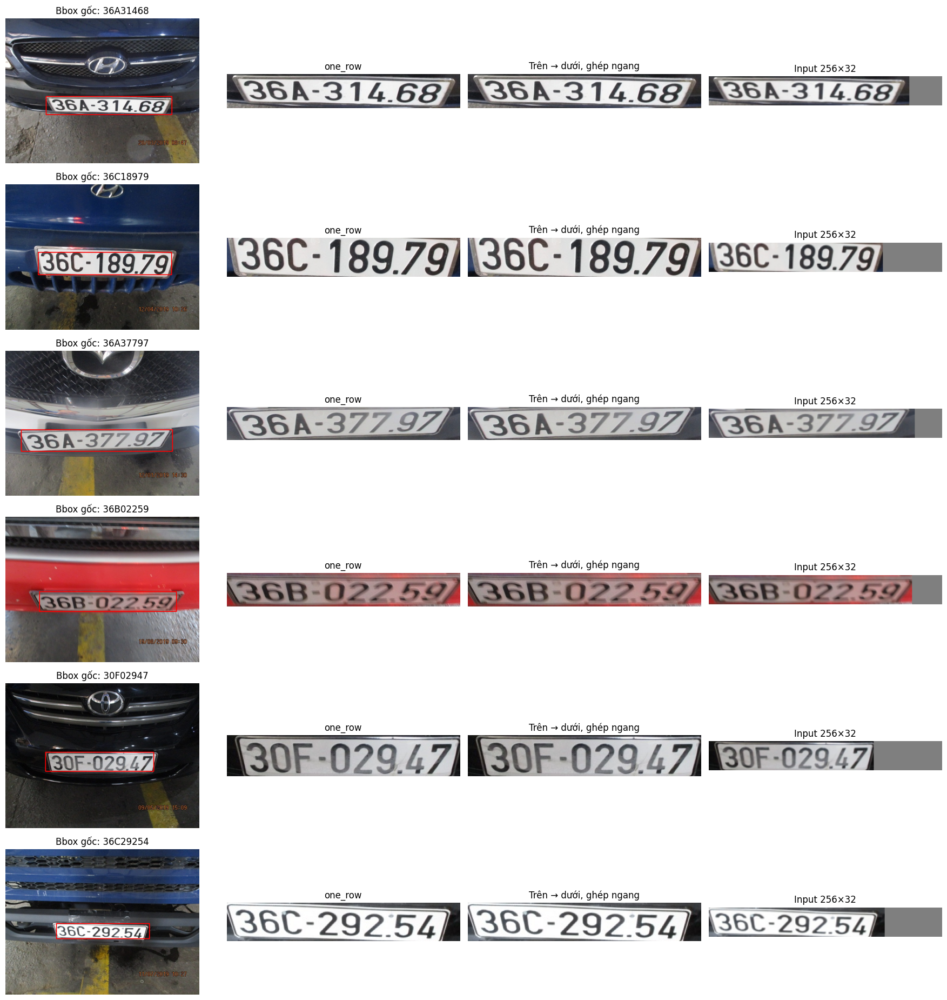

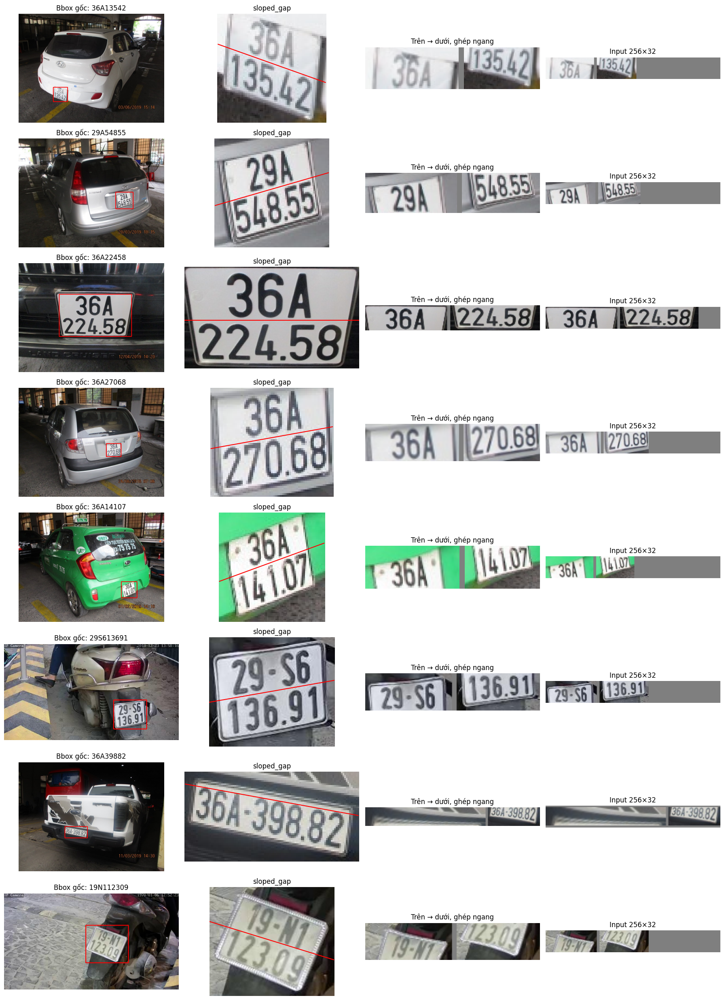

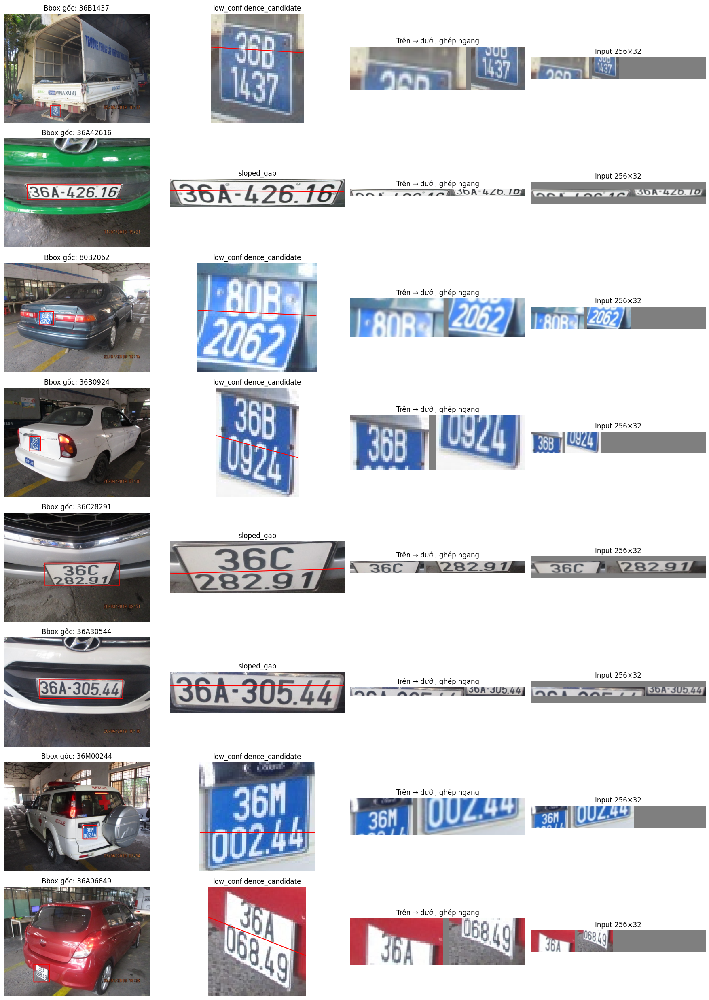

In [12]:
def show_pipeline(frame, n=8, seed=SEED):
    candidates=frame[frame.valid]
    if candidates.empty:
        print('Không có crop hợp lệ'); return
    chosen=candidates.sample(min(n,len(candidates)),random_state=seed)
    fig,axes=plt.subplots(len(chosen),4,figsize=(18,3.1*len(chosen)),squeeze=False)
    for axs,(_,r) in zip(axes,chosen.iterrows()):
        image,info,dbg=preprocess(r,True)
        src=dbg['original'].copy()
        x1,y1,x2,y2=bbox_for(r)
        cv2.rectangle(src,(x1,y1),(x2,y2),(255,0,0),2)
        axs[0].imshow(src); axs[0].set_title('Bbox gốc: '+r.text)
        axs[1].imshow(dbg['crop'])
        if info['split_y'] is not None:
            boundary=dbg['cut_line']; boundary=np.full(dbg['crop'].shape[1],boundary) if np.ndim(boundary)==0 else boundary
            axs[1].plot(np.arange(len(boundary)),boundary,color='red')
        axs[1].set_title(info['split_method'])
        axs[2].imshow(dbg['line']); axs[2].set_title('Trên → dưới, ghép ngang')
        axs[3].imshow(image); axs[3].set_title(f'Input {WIDTH}×{HEIGHT}')
        for ax in axs: ax.axis('off')
    plt.tight_layout(); plt.show()
# Không dùng test để chọn tiền xử lý.
show_pipeline(df[(df.split=='train') & (df.layout=='one_row')],6)
show_pipeline(df[(df.split=='train') & (df.layout=='two_rows')],8)
show_pipeline(df[(df.split=='val') & df.quality_review],8,seed=13)

**Điểm dừng audit:** nếu bbox sai hàng loạt, đổi BBOX_MODE và chạy lại từ đầu trong RUN_DIR mới.
Nếu khe đỏ xuyên ký tự, tạo manual_overrides.csv (image_id,split_y_frac) sau khi xem ảnh, hoặc nâng cấp bộ tìm hàng. split_y_frac tính theo crop có margin.
Các cảnh báo blur/nhãn dài chưa chứng minh ảnh sai. Không xóa ảnh khó để tăng điểm.

Xem ảnh một hàng phải còn đủ ký tự. Xem ảnh hai hàng phải còn đủ hai dòng và đúng thứ tự. Kiểm tra đặc biệt biển nghiêng, chữ sát mép, ảnh cháy sáng. Chỉ bật AUDIT_REVIEWED sau bước này.
Lần chạy đầu nên dùng augmentation nhẹ phía dưới; không threshold ảnh RGB đầu vào, không flip và không cắt ngẫu nhiên mất chữ.

Số ảnh cần xem: 1438


,image_id,text,layout,suggested_layout,crop_ratio,split
0,detection/one_row/1_1010_1_36A38587_102_344_22...,36A38587,one_row,two_rows,1.821918,train
1,detection/one_row/1_1017_1_36A38600_96_293_200...,36A38600,one_row,two_rows,1.447368,test
2,detection/one_row/1_1018_1_36A38601_70_327_195...,36A38601,one_row,two_rows,1.750000,train
3,detection/one_row/1_1022_1_36A38611_519_292_59...,36A38611,one_row,two_rows,1.472727,train
4,detection/one_row/1_1023_1_36A38611_483_291_56...,36A38611,one_row,two_rows,1.446429,train
5,detection/one_row/1_1025_1_36A38620_88_283_209...,36A38620,one_row,two_rows,1.417582,test
6,detection/one_row/1_1030_1_36A38628_72_325_180...,36A38628,one_row,two_rows,1.480519,test
7,detection/one_row/1_1038_1_36A38646_113_285_22...,36A38646,one_row,two_rows,1.769231,train
8,detection/one_row/1_1043_1_36A38655_76_262_190...,36A38655,one_row,two_rows,1.621622,train
9,detection/one_row/1_1053_1_36A38697_71_295_168...,36A38697,one_row,two_rows,1.337662,train


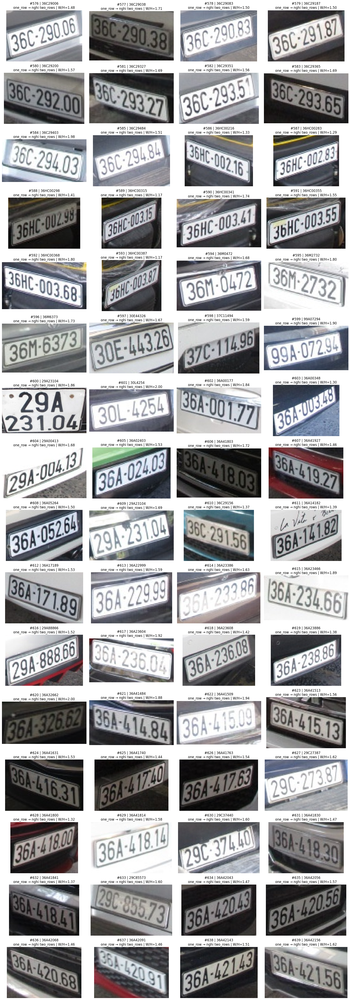

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert {"crop_width", "crop_height", "layout", "valid"} <= set(df.columns)

layout_review = df[df.valid].copy()
layout_review["crop_ratio"] = (
    layout_review.crop_width / layout_review.crop_height
)

# Ngưỡng gợi ý để tìm mẫu nghi vấn, chưa phải bộ phân loại layout.
layout_review["suggested_layout"] = np.select(
    [
        (layout_review.layout == "two_rows")
        & (layout_review.crop_ratio >= 2.5),

        (layout_review.layout == "one_row")
        & (layout_review.crop_ratio <= 2.0),
    ],
    ["one_row", "two_rows"],
    default="",
)

layout_suspects = layout_review[
    layout_review.suggested_layout != ""
].copy().reset_index(drop=True)

layout_suspects.to_csv(
    RUN_DIR / "layout_suspects.csv", index=False
)

print("Số ảnh cần xem:", len(layout_suspects))
display(
    layout_suspects[
        [
            "image_id", "text", "layout", "suggested_layout",
            "crop_ratio", "split",
        ]
    ].head(30)
)

def show_layout_suspects(page=0, page_size=16):
    """Chỉ xem crop gốc, không tách/ghép để tránh che lỗi layout."""
    subset = layout_suspects.iloc[
        page * page_size : (page + 1) * page_size
    ]

    if subset.empty:
        print("Không còn ảnh ở trang này.")
        return

    cols = 4
    rows = int(np.ceil(len(subset) / cols))
    fig, axes = plt.subplots(
        rows, cols,
        figsize=(18, rows * 3.2),
        squeeze=False,
    )

    for ax, (idx, row) in zip(axes.flat, subset.iterrows()):
        crop, _ = crop_plate(read_rgb(row.path), row)
        ax.imshow(crop)
        ax.set_title(
            f"#{idx} | {row.text}\n"
            f"{row.layout} → nghi {row.suggested_layout}"
            f" | W/H={row.crop_ratio:.2f}"
        )
        ax.axis("off")

    for ax in list(axes.flat)[len(subset):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_layout_suspects(page=9, page_size=64)

# Xem tiếp:
# show_layout_suspects(page=1)
# show_layout_suspects(page=2)

Tổng ảnh đã xác nhận: 1438
Ảnh cần đổi layout/cache: 112


Sửa layout và cập nhật cache:   0%|          | 0/112 [00:00<?, ?it/s]

Đã sửa thành công: 112
Không cần sửa vì đã one_row: 1326
Gặp lỗi: 0
Nhãn ký tự và split: giữ nguyên.


layout,one_row,two_rows
split,,
test,1903,1811
train,15372,14475
val,1923,1813


Hoàn tất cập nhật nhóm đã xác nhận.


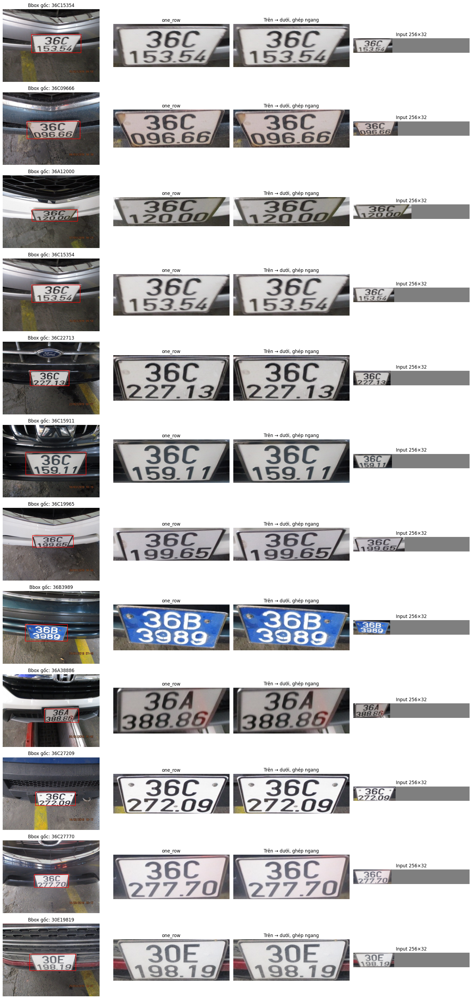

In [35]:
import hashlib
import json
from pathlib import Path
import pandas as pd
import cv2
from tqdm.auto import tqdm

assert "layout_suspects" in globals(), "Chưa có danh sách layout_suspects."
assert "df" in globals() and df.image_id.is_unique

# Tránh thay dữ liệu của một lần train đã có checkpoint.
assert not any(
    (RUN_DIR / name).exists()
    for name in ["crnn_best.pt", "crnn_last.pt"]
), "Đã có checkpoint trong RUN_DIR; chưa nên đổi dữ liệu của lần train đó."

# Toàn bộ danh sách này đã được bạn xác nhận là biển MỘT HÀNG.
confirmed_ids = set(layout_suspects.image_id)
assert confirmed_ids
assert confirmed_ids.issubset(set(df.image_id))

# Bỏ qua các mẫu đã sửa thành one_row trước đó.
to_fix = df[
    df.image_id.isin(confirmed_ids)
    & (df.layout != "one_row")
].copy()

print("Tổng ảnh đã xác nhận:", len(confirmed_ids))
print("Ảnh cần đổi layout/cache:", len(to_fix))

CACHE_DIR = Path(CACHE_DIR)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

if "layout_original" not in df.columns:
    df["layout_original"] = df["layout"]

# Lưu trạng thái để kiểm tra rằng nhãn và split không bị thay đổi.
before = df.set_index("image_id")[["text", "split"]].copy()

corrections_path = RUN_DIR / "layout_corrections.csv"
corrections = {}

if corrections_path.exists():
    previous = pd.read_csv(
        corrections_path, dtype=str, keep_default_na=False
    )
    corrections.update(zip(previous.image_id, previous.layout))

successful = []
failed = []

for idx, old_row in tqdm(
    to_fix.iterrows(),
    total=len(to_fix),
    desc="Sửa layout và cập nhật cache",
):
    image_id = old_row.image_id

    try:
        row = old_row.to_dict()
        row["layout"] = "one_row"

        # Với one_row, preprocess giữ nguyên biển, không tách hai hàng.
        image, info = preprocess(row)

        cache_path = CACHE_DIR / (
            hashlib.sha256(image_id.encode()).hexdigest() + ".png"
        )
        temp_path = cache_path.with_name(
            cache_path.stem + ".tmp.png"
        )

        written = cv2.imwrite(
            str(temp_path),
            cv2.cvtColor(image, cv2.COLOR_RGB2BGR),
        )
        if not written:
            raise RuntimeError("Không ghi được cache")

        temp_path.replace(cache_path)

        df.at[idx, "layout"] = "one_row"
        for key, value in info.items():
            df.at[idx, key] = value

        df.at[idx, "cache_path"] = str(cache_path)
        df.at[idx, "valid"] = True
        df.at[idx, "error"] = ""

        corrections[image_id] = "one_row"
        successful.append(image_id)

    except Exception as e:
        failed.append({
            "image_id": image_id,
            "error": str(e),
        })

# Cập nhật cờ chất lượng theo metadata mới.
df["quality_review"] = (
    ~df.valid.astype(bool)
    | ~df.split_ok.astype(bool)
    | (df.label_len < 7)
    | (df.label_len > 9)
    | (df.content_height.fillna(0) < 20)
    | (df.crop_height.fillna(0) < 16)
    | (df.blur.fillna(0) < 15)
)

assert df.set_index("image_id")[["text", "split"]].equals(before)

# Lưu kết quả sửa và metadata.
pd.DataFrame(
    sorted(corrections.items()),
    columns=["image_id", "layout"],
).to_csv(corrections_path, index=False)

df.to_csv(RUN_DIR / "metadata_audit.csv", index=False)

pd.DataFrame(
    failed, columns=["image_id", "error"]
).to_csv(RUN_DIR / "layout_fix_errors.csv", index=False)

# Ghi dấu phiên bản xử lý để checkpoint sắp train có thể truy vết.
PREPROCESS_CONFIG["layout_corrections_sha256"] = (
    hashlib.sha256(corrections_path.read_bytes()).hexdigest()
)

config_path = RUN_DIR / "config.json"
if config_path.exists():
    config = json.loads(config_path.read_text(encoding="utf-8"))
    config["preprocess"] = PREPROCESS_CONFIG
    config_path.write_text(
        json.dumps(config, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

if "RUN_IDENTITY" in globals():
    RUN_IDENTITY["preprocess"] = PREPROCESS_CONFIG

# Tạo lại các frame để không còn metadata layout cũ.
train_frame = df[
    (df.split == "train") & df.valid.astype(bool)
].copy()
val_frame = df[df.split == "val"].copy()
test_frame = df[df.split == "test"].copy()

# Nếu đã tạo DataLoader thì thay bằng loader dùng metadata mới.
if "make_loader" in globals():
    train_loader = make_loader(train_frame, True)
    val_loader = make_loader(val_frame)
    test_loader = make_loader(test_frame)

print("Đã sửa thành công:", len(successful))
print("Không cần sửa vì đã one_row:", len(confirmed_ids) - len(to_fix))
print("Gặp lỗi:", len(failed))
print("Nhãn ký tự và split: giữ nguyên.")

display(pd.crosstab(df.split, df.layout))

if failed:
    display(pd.DataFrame(failed))
else:
    print("Hoàn tất cập nhật nhóm đã xác nhận.")

# Xem lại ảnh sau sửa.
if successful:
    show_pipeline(
        df[df.image_id.isin(successful)],
        n=min(12, len(successful)),
    )

In [36]:
import hashlib
import json
from pathlib import Path

import cv2
import pandas as pd
from tqdm.auto import tqdm

assert "df" in globals()
assert "to_fix" in globals() and isinstance(to_fix, pd.DataFrame), (
    "Không còn bảng to_fix của lần sửa vừa rồi. "
    "Dừng lại để tránh hoàn tác nhầm các sửa chữa khác."
)
assert "successful" in globals(), (
    "Không còn danh sách successful của lần sửa hàng loạt."
)

assert not any(
    (RUN_DIR / name).exists()
    for name in ["crnn_best.pt", "crnn_last.pt"]
), "Đã có checkpoint; không thay dữ liệu của lần train đó tại đây."

# Chụp lại danh sách của lần sửa hàng loạt vừa rồi.
rollback_ids = set(successful)

assert df.image_id.is_unique
assert to_fix.image_id.is_unique
assert rollback_ids.issubset(set(df.image_id))
assert rollback_ids.issubset(set(to_fix.image_id))

# to_fix giữ layout ngay TRƯỚC lần sửa hàng loạt.
# Chính xác hơn việc hoàn tác mọi dòng có layout != layout_original.
restore_map = (
    to_fix[to_fix.image_id.isin(rollback_ids)]
    .set_index("image_id")["layout"]
    .to_dict()
)

assert set(restore_map.values()) <= {"one_row", "two_rows"}

before = df.set_index("image_id")[["text", "split"]].copy()
layouts_before = df.set_index("image_id")["layout"].copy()

CACHE_DIR = Path(CACHE_DIR)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

corrections_path = RUN_DIR / "layout_corrections.csv"
corrections = {}

if corrections_path.exists():
    saved = pd.read_csv(
        corrections_path, dtype=str, keep_default_na=False
    )
    corrections.update(zip(saved.image_id, saved.layout))

restored = []
rollback_errors = []

for image_id, old_layout in tqdm(
    restore_map.items(),
    total=len(restore_map),
    desc="Hoàn tác layout và tạo lại cache",
):
    idx = df.index[df.image_id == image_id][0]

    try:
        row = df.loc[idx].to_dict()
        row["layout"] = old_layout

        # Tạo lại input bằng layout trước lần sửa hàng loạt.
        image, info = preprocess(row)

        cache_path = CACHE_DIR / (
            hashlib.sha256(image_id.encode()).hexdigest() + ".png"
        )
        temp_path = cache_path.with_name(
            cache_path.stem + ".rollback.tmp.png"
        )

        written = cv2.imwrite(
            str(temp_path),
            cv2.cvtColor(image, cv2.COLOR_RGB2BGR),
        )
        if not written:
            raise RuntimeError("Không ghi được cache")

        temp_path.replace(cache_path)

        df.at[idx, "layout"] = old_layout
        for key, value in info.items():
            df.at[idx, key] = value

        df.at[idx, "cache_path"] = str(cache_path)
        df.at[idx, "valid"] = True
        df.at[idx, "error"] = ""

        # Ghi lại trạng thái khôi phục, giữ các correction khác.
        corrections[image_id] = old_layout
        restored.append(image_id)

    except Exception as e:
        rollback_errors.append({
            "image_id": image_id,
            "error": str(e),
        })

df["quality_review"] = (
    ~df.valid.astype(bool)
    | ~df.split_ok.astype(bool)
    | (df.label_len < 7)
    | (df.label_len > 9)
    | (df.content_height.fillna(0) < 20)
    | (df.crop_height.fillna(0) < 16)
    | (df.blur.fillna(0) < 15)
)

# Không đổi nhãn, split hoặc layout của các ảnh ngoài nhóm hoàn tác.
assert df.set_index("image_id")[["text", "split"]].equals(before)

untouched_ids = df.loc[
    ~df.image_id.isin(rollback_ids), "image_id"
]
assert (
    df.set_index("image_id")
      .loc[untouched_ids, "layout"]
      .equals(layouts_before.loc[untouched_ids])
)

pd.DataFrame(
    sorted(corrections.items()),
    columns=["image_id", "layout"],
).to_csv(corrections_path, index=False)

df.to_csv(RUN_DIR / "metadata_audit.csv", index=False)

pd.DataFrame(
    rollback_errors,
    columns=["image_id", "error"],
).to_csv(RUN_DIR / "layout_rollback_errors.csv", index=False)

PREPROCESS_CONFIG["layout_corrections_sha256"] = (
    hashlib.sha256(corrections_path.read_bytes()).hexdigest()
)

config_path = RUN_DIR / "config.json"
if config_path.exists():
    config = json.loads(config_path.read_text(encoding="utf-8"))
    config["preprocess"] = PREPROCESS_CONFIG
    config_path.write_text(
        json.dumps(config, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

if "RUN_IDENTITY" in globals():
    RUN_IDENTITY["preprocess"] = PREPROCESS_CONFIG

# Dataset/DataLoader cũ giữ bản sao metadata, nên tạo lại.
train_frame = df[
    (df.split == "train") & df.valid.astype(bool)
].copy()
val_frame = df[df.split == "val"].copy()
test_frame = df[df.split == "test"].copy()

if "make_loader" in globals():
    train_loader = make_loader(train_frame, True)
    val_loader = make_loader(val_frame)
    test_loader = make_loader(test_frame)

print("Đã hoàn tác và cập nhật cache:", len(restored), "ảnh")
print("Số ảnh gặp lỗi:", len(rollback_errors))
print("Giữ nguyên nhãn, split và các ảnh ngoài nhóm hoàn tác.")

if rollback_errors:
    display(pd.DataFrame(rollback_errors))

assert not rollback_errors, (
    "Một số ảnh chưa hoàn tác được. Xem lỗi bên trên trước khi tiếp tục."
)

display(pd.crosstab(df.split, df.layout))

Hoàn tác layout và tạo lại cache:   0%|          | 0/112 [00:00<?, ?it/s]

Đã hoàn tác và cập nhật cache: 112 ảnh
Số ảnh gặp lỗi: 0
Giữ nguyên nhãn, split và các ảnh ngoài nhóm hoàn tác.


layout,one_row,two_rows
split,,
test,1892,1822
train,15287,14560
val,1907,1829


Nhóm A — two_rows, nghi one_row: 112
Nhóm B — one_row, nghi two_rows: 1326
Nhóm B | trang 3/10 | chỉ số 384–511





,image_id,text,layout,crop_ratio,split
384,detection/one_row/4_1161_1_36C28462_448_308_52...,36C28462,one_row,1.355932,train
385,detection/one_row/4_1168_1_36C28540_105_296_17...,36C28540,one_row,1.636364,train
386,detection/one_row/4_1190_1_36D00664_480_299_55...,36D00664,one_row,1.230769,train
387,detection/one_row/4_1241_1_36M7915_478_219_549...,36M7915,one_row,1.363636,train
388,detection/one_row/4_1254_1_36N1174_472_248_543...,36N1174,one_row,1.875000,train
...,...,...,...,...,...
507,detection/one_row/5_223_1_36A01679_465_222_570...,36A01679,one_row,1.656716,train
508,detection/one_row/5_224_1_36A01837_108_223_203...,36A01837,one_row,1.741379,train
509,detection/one_row/5_231_1_36A02404_138_328_228...,36A02404,one_row,1.882353,val
510,detection/one_row/5_27_1_28C01040_125_324_207_...,28C01040,one_row,1.869565,train


In [53]:
import numpy as np
import matplotlib.pyplot as plt

review = df[df.valid.astype(bool)].copy()
review["crop_ratio"] = (
    review.crop_width / review.crop_height
)

# NHÓM A: hiện là hai hàng nhưng crop rộng.
# Cần xác nhận có thật sự là một hàng hay chỉ bị nghiêng phối cảnh.
suspects_to_one = (
    review[
        (review.layout == "two_rows")
        & (review.crop_ratio >= 2.5)
    ]
    .sort_values("image_id")
    .reset_index(drop=True)
)

# NHÓM B: hiện là một hàng nhưng crop khá vuông.
# Cần xác nhận có thật sự là hai hàng hay không.
suspects_to_two = (
    review[
        (review.layout == "one_row")
        & (review.crop_ratio <= 2.0)
    ]
    .sort_values("image_id")
    .reset_index(drop=True)
)

suspects_to_one.to_csv(
    RUN_DIR / "layout_review_A_to_one.csv", index=False
)
suspects_to_two.to_csv(
    RUN_DIR / "layout_review_B_to_two.csv", index=False
)

print("Nhóm A — two_rows, nghi one_row:", len(suspects_to_one))
print("Nhóm B — one_row, nghi two_rows:", len(suspects_to_two))

def show_layout_group(group="A", page=0, page_size=32):
    group = group.upper()
    assert group in {"A", "B"}
    assert page >= 0 and page_size > 0

    frame = suspects_to_one if group == "A" else suspects_to_two
    start = page * page_size
    subset = frame.iloc[start : start + page_size]
    total_pages = (len(frame) + page_size - 1) // page_size

    if subset.empty:
        print("Không có ảnh ở trang này.")
        return

    print(
        f"Nhóm {group} | trang {page}/{total_pages - 1} "
        f"| chỉ số {start}–{start + len(subset) - 1}"
    )

    cols = 4
    rows = int(np.ceil(len(subset) / cols))
    fig, axes = plt.subplots(
        rows, cols,
        figsize=(18, rows * 3.3),
        squeeze=False,
    )

    for ax, (idx, row) in zip(axes.flat, subset.iterrows()):
        # Luôn xem crop gốc, không xem ảnh đã tách/ghép.
        crop, _ = crop_plate(read_rgb(row.path), row)
        ax.imshow(crop)
        ax.set_title(
            f"{group}#{idx} | nhãn: {row.text}\n"
            f"Hiện tại: {row.layout} | W/H={row.crop_ratio:.2f}"
        )
        ax.axis("off")

    for ax in list(axes.flat)[len(subset):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    # Ánh xạ chỉ số trên hình sang image_id chính xác.
    display(
        subset[
            ["image_id", "text", "layout", "crop_ratio", "split"]
        ]
    )

# Xem riêng nhóm A trước.
show_layout_group(group="B", page=3, page_size=128)

# Các trang tiếp:
# show_layout_group(group="A", page=1, page_size=32)
# show_layout_group(group="A", page=2, page_size=32)

# Xem riêng nhóm B:
# show_layout_group(group="B", page=0, page_size=32)

Danh sách cập nhật chính xác:


,image_id,text,layout,split,new_layout
2166,detection/one_row/1_4015_1_36C25648_135_305_21...,36C25648,one_row,train,two_rows
2250,detection/one_row/1_4120_1_36C27682_119_278_19...,36C27682,one_row,train,two_rows
7743,detection/one_row/4_3181_1_36C27959_242_251_37...,36C27959,one_row,train,two_rows
13937,detection/one_row/7_2790_1_36A15181_178_220_40...,36A15181,one_row,val,two_rows
13964,detection/one_row/7_2817_1_36A16143_204_161_49...,36A16143,one_row,train,two_rows
22069,detection/two_rows/3_210_0_36A05680_213_245_29...,36A05680,two_rows,train,one_row
26896,detection/two_rows/6_1697_0_22A07557_119_235_5...,22A07557,two_rows,train,one_row
26899,detection/two_rows/6_1703_0_28C02747_142_271_5...,28C02747,two_rows,train,one_row
26978,detection/two_rows/6_2345_0_36A23747_115_239_5...,36A23747,two_rows,train,one_row
26991,detection/two_rows/6_2459_0_36A29035_95_246_55...,36A29035,two_rows,train,one_row


Chuẩn bị cache cho 21 ảnh:   0%|          | 0/21 [00:00<?, ?it/s]

Đã cập nhật: 16 ảnh → one_row; 5 ảnh → two_rows.
Đã tạm loại 1 ảnh bbox sai khỏi train.
Giữ nguyên ảnh gốc, nhãn ký tự và split.


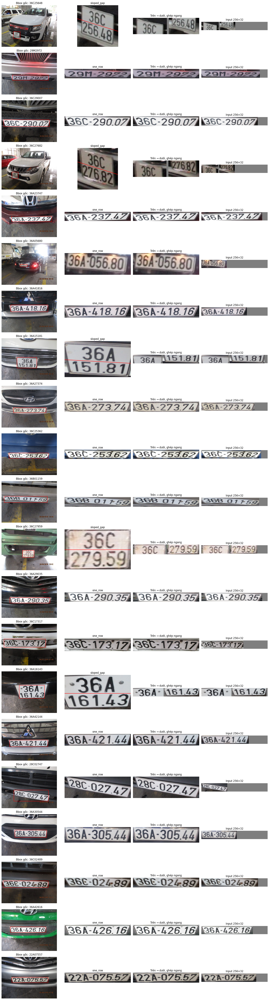

In [54]:
import hashlib
import json
from pathlib import Path

import cv2
import pandas as pd
from tqdm.auto import tqdm

assert df.image_id.is_unique
assert not any(
    (RUN_DIR / name).exists()
    for name in ["crnn_best.pt", "crnn_last.pt"]
), "Đã có checkpoint; chưa thay dữ liệu của lần train đó tại đây."

# A: tên file bị rút gọn trong bảng, dùng tiền tố đủ để nhận diện.
# Mỗi tiền tố bắt buộc chỉ khớp đúng MỘT ảnh.
A_PREFIXES = [
    "detection/two_rows/3_210_0_36A05680_",
    "detection/two_rows/6_1697_0_22A07557_",
    "detection/two_rows/6_1703_0_28C02747_",
    "detection/two_rows/6_2345_0_36A23747_",
    "detection/two_rows/6_2459_0_36A29035_",
    "detection/two_rows/6_2477_0_36A30544_",
    "detection/two_rows/6_2620_0_36A41816_",
    "detection/two_rows/6_2764_0_36A42144_",
    "detection/two_rows/6_2943_0_36B01159_",
    "detection/two_rows/6_3129_0_36C02489_",
    "detection/two_rows/6_3625_0_36C29007_",
    "detection/two_rows/6_4068_0_36C25362_",
    "detection/two_rows/7_2317_0_29M2972_",
    "detection/two_rows/7_3031_0_36A27374_",
    "detection/two_rows/7_3313_0_36A42616_",
    "detection/two_rows/7_4295_0_36C17317_",
]

B_FILES = [
    "detection/one_row/1_4015_1_36C25648_135_305_215_386.jpg",
    "detection/one_row/1_4120_1_36C27682_119_278_193_354.jpg",
    "detection/one_row/4_3181_1_36C27959_242_251_375_332.jpg",
    "detection/one_row/7_2790_1_36A15181_178_220_407_344.jpg",
    "detection/one_row/7_2817_1_36A16143_204_161_496_312.jpg",
]

BAD_BBOX_FILE = (
    "detection/one_row/1_3823_1_36C09937_6_232_83_295.jpg"
)

def resolve_prefix(prefix):
    matches = df.loc[
        df.image_id.str.startswith(prefix), "image_id"
    ].tolist()
    assert len(matches) == 1, (
        f"Tiền tố phải khớp đúng 1 ảnh: {prefix}\n"
        f"Đang khớp: {matches}"
    )
    return matches[0]

fixes = {
    resolve_prefix(prefix): "one_row"
    for prefix in A_PREFIXES
}

for image_id in B_FILES:
    assert image_id in set(df.image_id), f"Không thấy: {image_id}"
    fixes[image_id] = "two_rows"

assert BAD_BBOX_FILE in set(df.image_id)
assert BAD_BBOX_FILE not in fixes

# Trường hợp này bạn xác định thuộc train.
bad_idx = df.index[df.image_id == BAD_BBOX_FILE][0]
assert df.at[bad_idx, "split"] == "train"

print("Danh sách cập nhật chính xác:")
plan = df[df.image_id.isin(fixes)][
    ["image_id", "text", "layout", "split"]
].copy()
plan["new_layout"] = plan.image_id.map(fixes)
display(plan)
assert len(plan) == 21

before = df.set_index("image_id")[["text", "split"]].copy()
layouts_before = df.set_index("image_id").layout.copy()

if "layout_original" not in df.columns:
    df["layout_original"] = df.layout

CACHE_DIR = Path(CACHE_DIR)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

corrections_path = RUN_DIR / "layout_corrections.csv"
corrections = {}

if corrections_path.exists():
    previous = pd.read_csv(
        corrections_path, dtype=str, keep_default_na=False
    )
    corrections.update(zip(previous.image_id, previous.layout))

# Tạo toàn bộ ảnh mới trước khi cập nhật metadata/cache.
prepared = []

for image_id, new_layout in tqdm(
    fixes.items(), desc="Chuẩn bị cache cho 21 ảnh"
):
    idx = df.index[df.image_id == image_id][0]
    row = df.loc[idx].to_dict()
    row["layout"] = new_layout

    image, info = preprocess(row)
    cache_path = CACHE_DIR / (
        hashlib.sha256(image_id.encode()).hexdigest() + ".png"
    )
    prepared.append(
        (idx, image_id, new_layout, image, info, cache_path)
    )

for idx, image_id, new_layout, image, info, cache_path in prepared:
    temp_path = cache_path.with_name(
        cache_path.stem + ".confirmed.tmp.png"
    )

    written = cv2.imwrite(
        str(temp_path),
        cv2.cvtColor(image, cv2.COLOR_RGB2BGR),
    )
    assert written, f"Không ghi được cache: {image_id}"
    temp_path.replace(cache_path)

    df.at[idx, "layout"] = new_layout
    for key, value in info.items():
        df.at[idx, key] = value

    df.at[idx, "cache_path"] = str(cache_path)
    df.at[idx, "valid"] = True
    df.at[idx, "error"] = ""
    corrections[image_id] = new_layout

# Bbox sai: tạm loại khỏi train, không xóa ảnh gốc.
df.at[bad_idx, "valid"] = False
df.at[bad_idx, "error"] = "manual_review: bbox không bao đúng biển số"
df.at[bad_idx, "split_ok"] = False
df.at[bad_idx, "split_method"] = "invalid_bbox"

df["quality_review"] = (
    ~df.valid.astype(bool)
    | ~df.split_ok.astype(bool)
    | (df.label_len < 7)
    | (df.label_len > 9)
    | (df.content_height.fillna(0) < 20)
    | (df.crop_height.fillna(0) < 16)
    | (df.blur.fillna(0) < 15)
)

# Nhãn và split phải giữ nguyên.
assert df.set_index("image_id")[["text", "split"]].equals(before)

# Các ảnh ngoài 21 file không bị đổi layout.
untouched = df.loc[~df.image_id.isin(fixes), "image_id"]
assert (
    df.set_index("image_id").loc[untouched, "layout"]
    .equals(layouts_before.loc[untouched])
)

pd.DataFrame(
    sorted(corrections.items()),
    columns=["image_id", "layout"],
).to_csv(corrections_path, index=False)

# Lưu danh sách crop invalid để truy vết.
quarantine_path = RUN_DIR / "ocr_quarantine.csv"
df[~df.valid.astype(bool)][
    ["image_id", "text", "layout", "split", "error"]
].to_csv(quarantine_path, index=False)

df.to_csv(RUN_DIR / "metadata_audit.csv", index=False)

PREPROCESS_CONFIG["layout_corrections_sha256"] = (
    hashlib.sha256(corrections_path.read_bytes()).hexdigest()
)
PREPROCESS_CONFIG["quarantine_sha256"] = (
    hashlib.sha256(quarantine_path.read_bytes()).hexdigest()
)

config_path = RUN_DIR / "config.json"
if config_path.exists():
    config = json.loads(config_path.read_text(encoding="utf-8"))
    config["preprocess"] = PREPROCESS_CONFIG
    config_path.write_text(
        json.dumps(config, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

if "RUN_IDENTITY" in globals():
    RUN_IDENTITY["preprocess"] = PREPROCESS_CONFIG

# Cập nhật dữ liệu đang dùng, không chạy lại từ đầu.
train_frame = df[
    (df.split == "train") & df.valid.astype(bool)
].copy()
val_frame = df[df.split == "val"].copy()
test_frame = df[df.split == "test"].copy()

if "make_loader" in globals():
    train_loader = make_loader(train_frame, True)
    val_loader = make_loader(val_frame)
    test_loader = make_loader(test_frame)

assert BAD_BBOX_FILE not in set(train_frame.image_id)

print("Đã cập nhật: 16 ảnh → one_row; 5 ảnh → two_rows.")
print("Đã tạm loại 1 ảnh bbox sai khỏi train.")
print("Giữ nguyên ảnh gốc, nhãn ký tự và split.")

# Xem lại đúng các ảnh vừa cập nhật.
show_pipeline(df[df.image_id.isin(fixes)], n=21)

In [58]:
from pathlib import Path
import hashlib
import pandas as pd

bad_id = "detection/one_row/1_3823_1_36C09937_6_232_83_295.jpg"

assert not any(
    (RUN_DIR / name).exists()
    for name in ["crnn_best.pt", "crnn_last.pt"]
), "Đã có checkpoint; không đổi dataset giữa lần train."

matches = df[df.image_id == bad_id]
assert len(matches) == 1, "Không tìm thấy đúng một mẫu cần xóa."

# Xác minh chỉ xóa đúng file bên trong thư mục dữ liệu local.
source = Path(matches.iloc[0].path).resolve()
expected = (Path(LOCAL_ROOT) / bad_id).resolve()
assert source == expected
assert source.is_relative_to(Path(LOCAL_ROOT).resolve())

cache = (
    Path(CACHE_DIR)
    / (hashlib.sha256(bad_id.encode()).hexdigest() + ".png")
).resolve()
assert cache.is_relative_to(Path(CACHE_DIR).resolve())

# Lưu thông tin mẫu bị loại để truy vết.
matches.to_csv(RUN_DIR / "removed_bad_bbox_sample.csv", index=False)

source.unlink(missing_ok=True)
cache.unlink(missing_ok=True)

df = df[df.image_id != bad_id].copy().reset_index(drop=True)
df.to_csv(RUN_DIR / "metadata_audit.csv", index=False)

# Chỉ bỏ một mẫu khỏi manifest; không chia lại các ảnh còn lại.
split_path = RUN_DIR / "split_manifest.csv"
manifest = pd.read_csv(
    split_path, dtype=str, keep_default_na=False
)
manifest = manifest[manifest.image_id != bad_id]
manifest.to_csv(split_path, index=False)

SPLIT_HASH = hashlib.sha256(split_path.read_bytes()).hexdigest()
manifest_hash = hashlib.sha256(
    df[["image_id", "text", "layout"]]
      .sort_values("image_id")
      .to_csv(index=False)
      .encode()
).hexdigest()

if "RUN_IDENTITY" in globals():
    RUN_IDENTITY["split_hash"] = SPLIT_HASH
    RUN_IDENTITY["manifest_hash"] = manifest_hash

train_frame = df[
    (df.split == "train") & df.valid.astype(bool)
].copy()
val_frame = df[df.split == "val"].copy()
test_frame = df[df.split == "test"].copy()

if "make_loader" in globals():
    train_loader = make_loader(train_frame, True)
    val_loader = make_loader(val_frame)
    test_loader = make_loader(test_frame)

assert bad_id not in set(df.image_id)
print("Đã xóa đúng 1 ảnh local và cache; đã cập nhật dữ liệu train.")

Đã xóa đúng 1 ảnh local và cache; đã cập nhật dữ liệu train.


In [59]:
assert AUDIT_REVIEWED, 'Hãy xem audit/overlay, sửa dữ liệu nếu cần, rồi đặt AUDIT_REVIEWED=True ở cấu hình.'
assert df[(df.split=='train') & df.valid].shape[0] >= SANITY_SIZE
char_to_idx={c:i+1 for i,c in enumerate(CHARSET)}
idx_to_char={i+1:c for i,c in enumerate(CHARSET)}
NUM_CLASSES=len(CHARSET)+1
BLANK=0

def augment_rgb(image):
    im=Image.fromarray(image)
    if random.random()<.7:
        im=ImageEnhance.Brightness(im).enhance(random.uniform(.8,1.2))
        im=ImageEnhance.Contrast(im).enhance(random.uniform(.8,1.2))
    if random.random()<.12:
        im=im.filter(ImageFilter.GaussianBlur(random.uniform(.1,.6)))
    return np.asarray(im).copy()

class PlateDataset(Dataset):
    def __init__(self,frame,augment=False):
        self.rows=frame.to_dict('records'); self.augment=augment
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        row=self.rows[i]
        # Chỉ valid trong train. Val/test giữ mọi mẫu; invalid được tính sai rõ ràng.
        if bool(row['valid']):
            # Cache PNG lossless đã tạo khi audit; không tìm khe lại ở mỗi epoch.
            if row.get('cache_path') and Path(row['cache_path']).is_file():
                image=read_rgb(row['cache_path'])
            else:
                image,_=preprocess(row)
            if self.augment: image=augment_rgb(image)
        else:
            image=np.full((HEIGHT,WIDTH,3),127,np.uint8)
        tensor=torch.from_numpy(image.copy()).permute(2,0,1).float()/127.5-1
        return tensor,row

def collate(batch):
    images,rows=zip(*batch)
    targets=torch.tensor([char_to_idx[c] for r in rows for c in r['text']],dtype=torch.long)
    lengths=torch.tensor([len(r['text']) for r in rows],dtype=torch.long)
    return torch.stack(images), targets, lengths, list(rows)

def worker_seed(worker_id):
    seed=torch.initial_seed()%2**32
    random.seed(seed); np.random.seed(seed)

def make_loader(frame,training=False,batch_size=BATCH_SIZE,workers=NUM_WORKERS):
    return DataLoader(PlateDataset(frame,augment=training),batch_size=batch_size,
                      shuffle=training,num_workers=workers,pin_memory=DEVICE.type=='cuda',
                      persistent_workers=workers>0,collate_fn=collate,
                      worker_init_fn=worker_seed,
                      generator=torch.Generator().manual_seed(SEED))
train_frame=df[(df.split=='train') & df.valid].copy()
val_frame=df[df.split=='val'].copy()
test_frame=df[df.split=='test'].copy()
print('Train loại crop không hợp lệ:',int(((df.split=='train') & ~df.valid).sum()))
print('Val/test giữ cả crop invalid để tính lỗi.')
train_loader=make_loader(train_frame,True)
val_loader=make_loader(val_frame)
test_loader=make_loader(test_frame)

Train loại crop không hợp lệ: 0
Val/test giữ cả crop invalid để tính lỗi.


## 4. CRNN từ đầu, kiểm tra CTC
Input [B,3,32,256] → CNN [B,512,1,64] → [B,64,512] → BiLSTM → [T,B,37].
Giảm chiều rộng 4 lần, chiều cao 32 lần. 2 lớp BiLSTM, 256 hidden/hướng.
Toàn chiều rộng cố định kể cả padding được đưa vào chuỗi CTC; không giả dùng variable-length.
Loss FP32; blank=0; target không có blank. Điều kiện mỗi mẫu: T ≥ L + số cặp lặp liền nhau.
Không dùng zero_infinity để che lỗi độ dài.

In [60]:
class CRNN(nn.Module):
    def __init__(self,num_classes=NUM_CLASSES,hidden=256):
        super().__init__()
        def block(cin,cout):
            return [nn.Conv2d(cin,cout,3,padding=1,bias=False),
                    nn.BatchNorm2d(cout),nn.ReLU(inplace=True)]
        self.cnn=nn.Sequential(
            *block(3,64), nn.MaxPool2d(2,2),
            *block(64,128), nn.MaxPool2d(2,2),
            *block(128,256), *block(256,256), nn.MaxPool2d((2,1),(2,1)),
            *block(256,512), *block(512,512), nn.MaxPool2d((2,1),(2,1)),
            nn.Conv2d(512,512,(2,1),bias=False),nn.BatchNorm2d(512),nn.ReLU(inplace=True))
        self.rnn=nn.LSTM(512,hidden,num_layers=2,batch_first=True,
                         bidirectional=True,dropout=.1)
        self.head=nn.Linear(hidden*2,num_classes)
        self.apply(self._init)
    @staticmethod
    def _init(m):
        if isinstance(m,nn.Conv2d): nn.init.kaiming_normal_(m.weight,nonlinearity='relu')
        elif isinstance(m,nn.Linear):
            nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    def forward(self,x):
        f=self.cnn(x)
        assert f.shape[2]==1, f'Feature height must be 1: {f.shape}'
        seq=f.squeeze(2).transpose(1,2)
        seq,_=self.rnn(seq)
        return self.head(seq).transpose(0,1)  # logits [T,B,C], log_softmax ngoài autocast

def minimum_ctc_steps(text):
    return len(text)+sum(a==b for a,b in zip(text,text[1:]))

seed_all(SEED)
probe_model=CRNN().to(DEVICE).eval()
with torch.no_grad():
    probe=probe_model(torch.zeros(2,3,HEIGHT,WIDTH,device=DEVICE))
T_STEPS=probe.shape[0]
assert probe.shape==(WIDTH//4,2,NUM_CLASSES)
assert max(df.text.map(minimum_ctc_steps))<=T_STEPS
print('Output:',tuple(probe.shape),'Parameters:',sum(p.numel() for p in probe_model.parameters()))
del probe_model,probe
if DEVICE.type=='cuda': torch.cuda.empty_cache()
criterion=nn.CTCLoss(blank=BLANK,reduction='mean',zero_infinity=False)

def greedy_decode(logits):
    sequences=logits.detach().argmax(2).transpose(0,1).cpu().tolist()
    results=[]
    for seq in sequences:
        previous=None; chars=[]
        for idx in seq:
            if idx!=BLANK and idx!=previous: chars.append(idx_to_char[idx])
            previous=idx
        results.append(''.join(chars))
    return results

def edit_distance(a,b):
    prev=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        cur=[i]
        for j,cb in enumerate(b,1):
            cur.append(min(cur[-1]+1,prev[j]+1,prev[j-1]+(ca!=cb)))
        prev=cur
    return prev[-1]

def summarize(details):
    assert len(details)
    return dict(samples=len(details),
                sequence_accuracy=float((details.target==details.prediction).mean()),
                cer=float(sum(edit_distance(a,b) for a,b in zip(details.target,details.prediction))
                          /max(1,details.target.str.len().sum())),
                empty_rate=float((details.prediction=='').mean()),
                invalid_inputs=int((~details.valid).sum()))

def ctc_loss(logits,targets,lengths,rows):
    t,b,_=logits.shape
    assert all(minimum_ctc_steps(r['text'])<=t for r in rows)
    inputs=torch.full((b,),t,dtype=torch.long)  # lengths CPU
    loss=criterion(logits.float().log_softmax(2),targets.to(DEVICE),inputs,lengths.cpu())
    if not torch.isfinite(loss): raise RuntimeError('CTC loss NaN/Inf — dừng để kiểm tra dữ liệu/gradient')
    return loss

Output: (64, 2, 37) Parameters: 8200805


## 5. Sanity: ghi nhớ 32 ảnh trước khi train lớn
Chọn các ảnh một hàng ít cờ rủi ro; đây chỉ là lọc ứng viên, vẫn phải xem ảnh.
Tắt augmentation/dropout cho bài kiểm tra này. Model sanity bị bỏ sau kiểm tra.
Nếu không đạt ≥95% trên chính tập nhỏ trong 600 bước, dừng xem nhãn, crop, CTC, learning rate. Không kết luận do thiếu epoch trên toàn bộ tập.

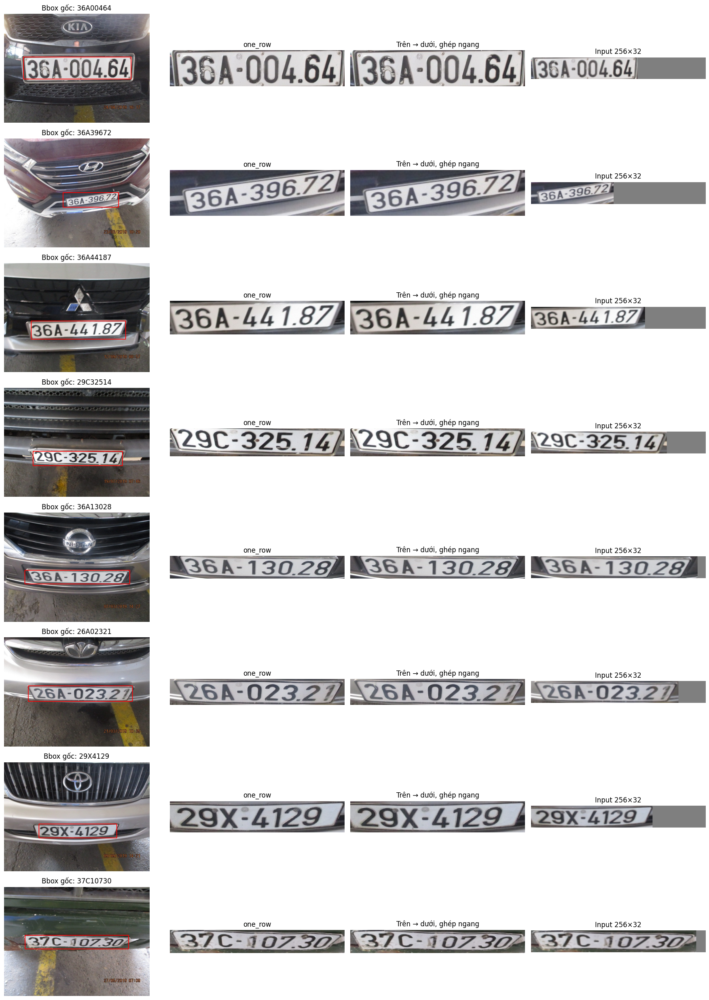

sanity 1: loss=24.7875, exact=0.000, sample=['', '', '']
sanity 25: loss=2.4823, exact=0.000, sample=['', '', '']
sanity 50: loss=2.1432, exact=0.000, sample=['3', '', '3']
sanity 75: loss=1.7957, exact=0.000, sample=['3', '', '3']
sanity 100: loss=1.4200, exact=0.000, sample=['36A', '36A4', '36']
sanity 125: loss=0.9833, exact=0.000, sample=['36C9', '369', '36A']
sanity 150: loss=0.6686, exact=0.000, sample=['36C25', '36D5', '36A']
sanity 175: loss=0.3329, exact=0.094, sample=['36C425', '36D058', '36A']
sanity 200: loss=0.1354, exact=0.500, sample=['36C00425', '36D0458', '36A']
sanity 225: loss=0.0721, exact=0.625, sample=['36C00425', '36D0458', '36A3783']
sanity 250: loss=0.0442, exact=0.781, sample=['36C00425', '36D00458', '36A3783']
sanity 275: loss=0.0248, exact=0.938, sample=['36C00425', '36D00458', '36A37813']
sanity 300: loss=0.0151, exact=0.938, sample=['36C00425', '36D00458', '36A37813']
sanity 325: loss=0.0106, exact=0.938, sample=['36C00425', '36D00458', '36A37813']
sanity 

In [61]:
sanity_candidates=train_frame[(train_frame.layout=='one_row') & ~train_frame.quality_review]
assert len(sanity_candidates)>=SANITY_SIZE
sanity_frame=sanity_candidates.sample(SANITY_SIZE,random_state=SEED)
show_pipeline(sanity_frame,8)
# Có thể thay sanity_frame bằng danh sách image_id đã kiểm tra thủ công.
if RUN_SANITY:
    seed_all(SEED)
    sanity=CRNN().to(DEVICE)
    for module in sanity.modules():
        if isinstance(module,nn.LSTM): module.dropout=0.
        if isinstance(module,nn.Dropout): module.p=0.
    sl=make_loader(sanity_frame,batch_size=SANITY_SIZE,workers=0)
    images,targets,lengths,rows=next(iter(sl))
    images=images.to(DEVICE)
    opt=torch.optim.AdamW(sanity.parameters(),lr=LR,weight_decay=0)
    best_sanity=0.
    for step in range(1,SANITY_STEPS+1):
        sanity.train(); opt.zero_grad(set_to_none=True)
        logits=sanity(images); loss=ctc_loss(logits,targets,lengths,rows)
        loss.backward(); nn.utils.clip_grad_norm_(sanity.parameters(),5); opt.step()
        if step%25==0 or step==1:
            sanity.eval()
            with torch.no_grad(): preds=greedy_decode(sanity(images))
            acc=np.mean([p==r['text'] for p,r in zip(preds,rows)])
            best_sanity=max(best_sanity,float(acc))
            print(f'sanity {step}: loss={loss.item():.4f}, exact={acc:.3f}, sample={preds[:3]}')
            if acc>=SANITY_MIN_ACC: break
    json_save(dict(best_accuracy=best_sanity,steps=step),RUN_DIR/'sanity_metrics.json')
    del sanity,opt,images,logits,loss
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
    assert best_sanity>=SANITY_MIN_ACC, 'Sanity chưa đạt. Kiểm tra input/model trước train đầy đủ.'
else:
    print('Đã bỏ qua sanity theo cấu hình; nên chạy ít nhất một lần.')

## 6. Train đầy đủ và checkpoint
Khởi tạo model mới hoàn toàn sau sanity. AdamW, clipping, AMP cho CNN/LSTM nhưng CTC ở FP32.
Train accuracy là online trên ảnh augmentation, không so trực tiếp với val để kết luận underfit/overfit.
Checkpoint chọn theo val exact accuracy, tie-break CER. Early stopping và giảm LR theo val.
Lưu best, last, lịch sử, RNG, optimizer/scheduler/scaler và fingerprint split/preprocess để resume.
Resume tại ranh giới epoch; thứ tự worker/augmentation có thể khác một lần chạy liên tục.

In [63]:
USE_AMP = False
print("Đã tắt AMP; lần train tiếp theo dùng FP32.")

Đã tắt AMP; lần train tiếp theo dùng FP32.


In [64]:
def run_epoch(model,loader,optimizer=None,scaler=None):
    training=optimizer is not None
    model.train(training)
    total_loss=0.; loss_count=0; records=[]
    with torch.set_grad_enabled(training):
        for images,targets,lengths,rows in tqdm(loader,desc='train' if training else 'eval',leave=False):
            images=images.to(DEVICE,non_blocking=True)
            if training: optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=DEVICE.type,enabled=USE_AMP and DEVICE.type=='cuda'):
                logits=model(images)
            # Loại invalid khỏi loss val/test, nhưng KHÔNG loại khỏi denominator accuracy/CER.
            valid=[i for i,r in enumerate(rows) if bool(r['valid'])]
            loss=None
            if valid:
                selected=[rows[i] for i in valid]
                vtargets=torch.tensor([char_to_idx[c] for r in selected for c in r['text']],dtype=torch.long)
                vlens=torch.tensor([len(r['text']) for r in selected],dtype=torch.long)
                loss=ctc_loss(logits[:,valid,:],vtargets,vlens,selected)
                total_loss+=float(loss.detach())*len(valid); loss_count+=len(valid)
            if training:
                assert len(valid)==len(rows) and loss is not None
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
                scaler.step(optimizer); scaler.update()
            predictions=greedy_decode(logits)
            for r,p in zip(rows,predictions):
                if not bool(r['valid']): p=''
                records.append(dict(image_id=r['image_id'],target=r['text'],prediction=p,
                                    layout=r['layout'],valid=bool(r['valid']),
                                    split_ok=bool(r['split_ok']),quality_review=bool(r['quality_review']),
                                    label_len=len(r['text'])))
    details=pd.DataFrame(records)
    details['correct']=details.target==details.prediction
    details['edit_distance']=[edit_distance(a,b) for a,b in zip(details.target,details.prediction)]
    metrics=summarize(details)
    metrics['loss_valid_inputs']=total_loss/max(1,loss_count)
    return metrics,details

def rng_state():
    return dict(python=random.getstate(),numpy=np.random.get_state(),torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)
def restore_rng(state):
    random.setstate(state['python']); np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    if torch.cuda.is_available() and state['cuda'] is not None:
        torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda']])

seed_all(SEED)
model=CRNN().to(DEVICE)
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='max',factor=.5,patience=3,min_lr=1e-6)
scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP and DEVICE.type=='cuda')
BEST_PATH=RUN_DIR/'crnn_best.pt'
LAST_PATH=RUN_DIR/'crnn_last.pt'
history=[]; start_epoch=1; best_key=(-1.,-float('inf')); stale=0
# Fingerprint overrides: đổi xử lý giữa run phải dùng RUN_DIR mới.
override_hash=hashlib.sha256(OVERRIDES_CSV.read_bytes()).hexdigest() if OVERRIDES_CSV.exists() else 'none'
RUN_IDENTITY=dict(split_hash=SPLIT_HASH,manifest_hash=manifest_hash,
                  preprocess=PREPROCESS_CONFIG,override_hash=override_hash)
if LAST_PATH.exists() and not RESUME:
    raise RuntimeError('RUN_DIR đã có checkpoint. Đặt RESUME=True hoặc chọn RUN_DIR mới.')
if RESUME:
    assert LAST_PATH.exists()
    state=torch.load(LAST_PATH,map_location='cpu',weights_only=False) # chỉ checkpoint tự tạo
    assert state['identity']==RUN_IDENTITY, 'Split hoặc tiền xử lý khác checkpoint'
    model.load_state_dict(state['model'])
    optimizer.load_state_dict(state['optimizer']); scheduler.load_state_dict(state['scheduler'])
    scaler.load_state_dict(state['scaler'])
    history=state['history']; start_epoch=state['epoch']+1
    best_key=tuple(state['best_key']); stale=state['stale']
    restore_rng(state['rng'])
    print('Resume epoch',start_epoch)
json_save(RUN_IDENTITY,RUN_DIR/'run_identity.json')

for epoch in range(start_epoch,EPOCHS+1):
    begin=time.perf_counter()
    tm,_=run_epoch(model,train_loader,optimizer,scaler)
    vm,vd=run_epoch(model,val_loader)
    scheduler.step(vm['sequence_accuracy'])
    key=(vm['sequence_accuracy'],-vm['cer'])
    improved=key>best_key
    if improved: best_key=key; stale=0
    else: stale+=1
    history.append(dict(epoch=epoch,lr=optimizer.param_groups[0]['lr'],
                        seconds=time.perf_counter()-begin,
                        **{'train_'+k:v for k,v in tm.items()},
                        **{'val_'+k:v for k,v in vm.items()}))
    state=dict(model=model.state_dict(),optimizer=optimizer.state_dict(),
               scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),
               epoch=epoch,history=history,best_key=best_key,stale=stale,
               identity=RUN_IDENTITY,charset=CHARSET,val_metrics=vm,rng=rng_state())
    # File tạm + replace để tránh checkpoint nửa chừng khi quá trình ghi bị ngắt.
    tmp=RUN_DIR/'crnn_last.tmp'; torch.save(state,tmp); tmp.replace(LAST_PATH)
    if improved:
        tmp=RUN_DIR/'crnn_best.tmp'; torch.save(state,tmp); tmp.replace(BEST_PATH)
        vd.to_csv(RUN_DIR/'best_val_predictions.csv',index=False)
    pd.DataFrame(history).to_csv(RUN_DIR/'history.csv',index=False)
    print(f"Epoch {epoch:03d}: train={tm['sequence_accuracy']:.4f}, "
          f"val={vm['sequence_accuracy']:.4f}, CER={vm['cer']:.4f}, "
          f"empty={vm['empty_rate']:.3f}, best={best_key[0]:.4f}, "
          f"lr={optimizer.param_groups[0]['lr']:.2g}")
    if stale>=PATIENCE:
        print('Early stopping'); break
assert BEST_PATH.exists()
print('Best checkpoint:',BEST_PATH)

train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 001: train=0.1981, val=0.6127, CER=0.0873, empty=0.000, best=0.6127, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 002: train=0.7609, val=0.7883, CER=0.0454, empty=0.000, best=0.7883, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 003: train=0.8666, val=0.8975, CER=0.0214, empty=0.000, best=0.8975, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 004: train=0.9019, val=0.8897, CER=0.0227, empty=0.000, best=0.8975, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 005: train=0.9199, val=0.9087, CER=0.0196, empty=0.000, best=0.9087, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 006: train=0.9344, val=0.9087, CER=0.0187, empty=0.000, best=0.9087, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 007: train=0.9435, val=0.9170, CER=0.0172, empty=0.000, best=0.9170, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 008: train=0.9461, val=0.9074, CER=0.0192, empty=0.000, best=0.9170, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 009: train=0.9471, val=0.9218, CER=0.0160, empty=0.000, best=0.9218, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 010: train=0.9563, val=0.9253, CER=0.0160, empty=0.000, best=0.9253, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 011: train=0.9576, val=0.9184, CER=0.0161, empty=0.000, best=0.9253, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 012: train=0.9603, val=0.9267, CER=0.0155, empty=0.000, best=0.9267, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 013: train=0.9611, val=0.9261, CER=0.0154, empty=0.000, best=0.9267, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 014: train=0.9610, val=0.9277, CER=0.0148, empty=0.000, best=0.9277, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 015: train=0.9656, val=0.9376, CER=0.0133, empty=0.000, best=0.9376, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 016: train=0.9673, val=0.9296, CER=0.0147, empty=0.000, best=0.9376, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 017: train=0.9720, val=0.9325, CER=0.0141, empty=0.000, best=0.9376, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 018: train=0.9693, val=0.9328, CER=0.0135, empty=0.000, best=0.9376, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 019: train=0.9729, val=0.9406, CER=0.0128, empty=0.000, best=0.9406, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 020: train=0.9753, val=0.9390, CER=0.0128, empty=0.000, best=0.9406, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 021: train=0.9763, val=0.9331, CER=0.0135, empty=0.000, best=0.9406, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 022: train=0.9741, val=0.9336, CER=0.0135, empty=0.000, best=0.9406, lr=0.001


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 023: train=0.9751, val=0.9358, CER=0.0132, empty=0.000, best=0.9406, lr=0.0005


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 024: train=0.9875, val=0.9491, CER=0.0108, empty=0.000, best=0.9491, lr=0.0005


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 025: train=0.9922, val=0.9513, CER=0.0107, empty=0.000, best=0.9513, lr=0.0005


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 026: train=0.9933, val=0.9494, CER=0.0108, empty=0.000, best=0.9513, lr=0.0005


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 027: train=0.9939, val=0.9451, CER=0.0116, empty=0.000, best=0.9513, lr=0.0005


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 028: train=0.9922, val=0.9502, CER=0.0107, empty=0.000, best=0.9513, lr=0.0005


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 029: train=0.9914, val=0.9419, CER=0.0121, empty=0.000, best=0.9513, lr=0.00025


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 030: train=0.9945, val=0.9505, CER=0.0108, empty=0.000, best=0.9513, lr=0.00025


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 031: train=0.9974, val=0.9502, CER=0.0106, empty=0.000, best=0.9513, lr=0.00025


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 032: train=0.9976, val=0.9507, CER=0.0105, empty=0.000, best=0.9513, lr=0.00025


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 033: train=0.9981, val=0.9521, CER=0.0104, empty=0.000, best=0.9521, lr=0.00025


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 034: train=0.9984, val=0.9475, CER=0.0112, empty=0.000, best=0.9521, lr=0.00025


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 035: train=0.9982, val=0.9481, CER=0.0109, empty=0.000, best=0.9521, lr=0.00025


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 036: train=0.9979, val=0.9470, CER=0.0110, empty=0.000, best=0.9521, lr=0.00025


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 037: train=0.9985, val=0.9507, CER=0.0105, empty=0.000, best=0.9521, lr=0.00013


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 038: train=0.9987, val=0.9510, CER=0.0104, empty=0.000, best=0.9521, lr=0.00013


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 039: train=0.9993, val=0.9524, CER=0.0100, empty=0.000, best=0.9524, lr=0.00013


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 040: train=0.9993, val=0.9518, CER=0.0103, empty=0.000, best=0.9524, lr=0.00013


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 041: train=0.9991, val=0.9529, CER=0.0100, empty=0.000, best=0.9529, lr=0.00013


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 042: train=0.9996, val=0.9521, CER=0.0102, empty=0.000, best=0.9529, lr=0.00013


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 043: train=0.9991, val=0.9497, CER=0.0109, empty=0.000, best=0.9529, lr=0.00013


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 044: train=0.9991, val=0.9499, CER=0.0107, empty=0.000, best=0.9529, lr=0.00013


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 045: train=0.9995, val=0.9502, CER=0.0105, empty=0.000, best=0.9529, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 046: train=0.9996, val=0.9499, CER=0.0105, empty=0.000, best=0.9529, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 047: train=0.9994, val=0.9529, CER=0.0102, empty=0.000, best=0.9529, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 048: train=0.9996, val=0.9534, CER=0.0102, empty=0.000, best=0.9534, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 049: train=0.9998, val=0.9534, CER=0.0101, empty=0.000, best=0.9534, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 050: train=0.9998, val=0.9537, CER=0.0101, empty=0.000, best=0.9537, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 051: train=0.9997, val=0.9529, CER=0.0100, empty=0.000, best=0.9537, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 052: train=0.9998, val=0.9534, CER=0.0100, empty=0.000, best=0.9537, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 053: train=0.9996, val=0.9534, CER=0.0099, empty=0.000, best=0.9537, lr=6.3e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 054: train=0.9997, val=0.9529, CER=0.0099, empty=0.000, best=0.9537, lr=3.1e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 055: train=0.9999, val=0.9532, CER=0.0100, empty=0.000, best=0.9537, lr=3.1e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 056: train=0.9998, val=0.9540, CER=0.0099, empty=0.000, best=0.9540, lr=3.1e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 057: train=0.9998, val=0.9553, CER=0.0096, empty=0.000, best=0.9553, lr=3.1e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 058: train=0.9998, val=0.9545, CER=0.0098, empty=0.000, best=0.9553, lr=3.1e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 059: train=0.9996, val=0.9542, CER=0.0098, empty=0.000, best=0.9553, lr=3.1e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 060: train=0.9999, val=0.9540, CER=0.0098, empty=0.000, best=0.9553, lr=3.1e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 061: train=0.9998, val=0.9526, CER=0.0100, empty=0.000, best=0.9553, lr=1.6e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 062: train=0.9998, val=0.9516, CER=0.0101, empty=0.000, best=0.9553, lr=1.6e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 063: train=0.9999, val=0.9516, CER=0.0102, empty=0.000, best=0.9553, lr=1.6e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 064: train=0.9998, val=0.9537, CER=0.0098, empty=0.000, best=0.9553, lr=1.6e-05


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 065: train=0.9999, val=0.9534, CER=0.0099, empty=0.000, best=0.9553, lr=7.8e-06


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 066: train=0.9998, val=0.9532, CER=0.0099, empty=0.000, best=0.9553, lr=7.8e-06


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 067: train=0.9999, val=0.9537, CER=0.0098, empty=0.000, best=0.9553, lr=7.8e-06


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 068: train=0.9998, val=0.9529, CER=0.0099, empty=0.000, best=0.9553, lr=7.8e-06


train:   0%|          | 0/467 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 069: train=0.9998, val=0.9534, CER=0.0098, empty=0.000, best=0.9553, lr=3.9e-06
Early stopping
Best checkpoint: /content/drive/MyDrive/Computer Vision/DoAnCuoiKy/VNLP_CRNN_scratch_v1/crnn_best.pt


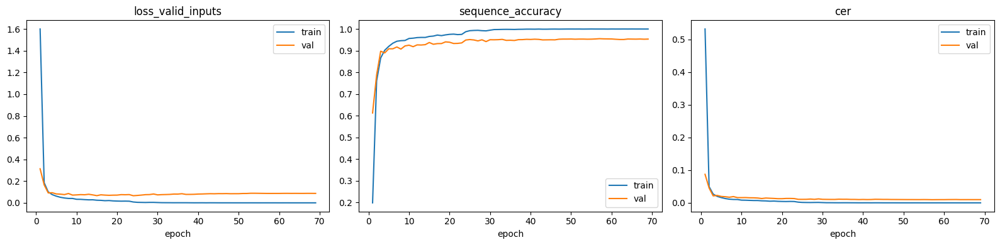

eval:   0%|          | 0/16 [00:00<?, ?it/s]

eval:   0%|          | 0/59 [00:00<?, ?it/s]

Train probe không augmentation: {'samples': 1024, 'sequence_accuracy': 1.0, 'cer': 0.0, 'empty_rate': 0.0, 'invalid_inputs': 0, 'loss_valid_inputs': 1.5453028339607044e-05}
Validation: {'samples': 3736, 'sequence_accuracy': 0.9552997858672377, 'cer': 0.009623416981321214, 'empty_rate': 0.0, 'invalid_inputs': 0, 'loss_valid_inputs': 0.08661124628974465}


In [65]:
hist=pd.read_csv(RUN_DIR/'history.csv')
fig,axs=plt.subplots(1,3,figsize=(16,4))
for metric,ax in zip(['loss_valid_inputs','sequence_accuracy','cer'],axs):
    for prefix in ['train','val']:
        ax.plot(hist.epoch,hist[prefix+'_'+metric],label=prefix)
    ax.set_title(metric); ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout(); plt.show()
# Chẩn đoán train/val công bằng hơn: eval một tập con train cố định, không augmentation.
checkpoint=torch.load(BEST_PATH,map_location='cpu',weights_only=False)
assert checkpoint['identity']==RUN_IDENTITY
model.load_state_dict(checkpoint['model']); model.to(DEVICE).eval()
probe_frame=train_frame.sample(min(1024,len(train_frame)),random_state=SEED)
train_probe,_=run_epoch(model,make_loader(probe_frame))
val_metrics,val_predictions=run_epoch(model,val_loader)
print('Train probe không augmentation:',train_probe)
print('Validation:',val_metrics)
json_save(dict(train_probe=train_probe,validation=val_metrics),RUN_DIR/'diagnostics.json')

## 7. Test cuối cùng và bảng lỗi
Chỉ bật RUN_FINAL_TEST khi đã chốt cấu hình bằng validation. Val/test giữ mẫu invalid với prediction rỗng.
Kết quả nhóm chất lượng chỉ để giải thích; accuracy chính tính trên toàn bộ split.
Đây là OCR với GT bbox; cần đánh giá YOLO crop riêng cho kết quả end-to-end.
Không sửa O/0 hoặc dùng luật biển số trong điểm greedy này.

eval:   0%|          | 0/59 [00:00<?, ?it/s]

TEST: {'samples': 3714, 'sequence_accuracy': 0.9504577275175013, 'cer': 0.00991263440860215, 'empty_rate': 0.0, 'invalid_inputs': 0, 'loss_valid_inputs': 0.07752184713334213}


,layout,samples,sequence_accuracy,cer,empty_rate,invalid_inputs
0,one_row,1894,0.955649,0.009379,0.0,0
1,two_rows,1820,0.945055,0.010450,0.0,0


,label_len,samples,sequence_accuracy,cer,empty_rate,invalid_inputs
0,7,371,0.938005,0.011167,0.0,0
1,8,2928,0.958675,0.008367,0.0,0
2,9,411,0.902676,0.018924,0.0,0
3,10,4,1.000000,0.000000,0.0,0


,split_ok,samples,sequence_accuracy,cer,empty_rate,invalid_inputs
0,False,5,0.4000,0.128205,0.0,0
1,True,3709,0.9512,0.009757,0.0,0


,quality_review,samples,sequence_accuracy,cer,empty_rate,invalid_inputs
0,False,3703,0.951121,0.009776,0.0,0
1,True,11,0.727273,0.052632,0.0,0


,image_id,target,prediction,layout,valid,split_ok,quality_review,label_len,correct,edit_distance
3606,detection/two_rows_label_xe_may/7_2584_0_14b12...,14B122004,36A919,two_rows,True,True,False,9,False,9
26,detection/one_row/1_2027_1_29A41952_71_208_480...,29A41952,80B935,one_row,True,True,False,8,False,7
531,detection/one_row/3_3362_1_36C28287_222_256_40...,36C28287,36B73,one_row,True,True,False,8,False,6
3568,detection/two_rows_label_xe_may/7_1395_0_23L31...,23L314767,24C675,two_rows,True,True,False,9,False,6
1840,detection/one_row/9_1_1_15A05176_481_306_557_3...,15A05176,36A06770,one_row,True,True,False,8,False,5
1883,detection/one_row/9_35_1_29D50237_478_302_554_...,29D50237,29H0470,one_row,True,True,False,8,False,5
458,detection/one_row/3_2519_1_36A40246_419_225_49...,36A40246,26A4,one_row,True,True,False,8,False,5
3169,detection/two_rows/9_884_0_36C18089_217_376_25...,36C18089,36B15558,two_rows,True,True,False,8,False,5
1994,detection/two_rows/1_29_0_29A04279_526_333_594...,29A04279,19A0916,two_rows,True,True,False,8,False,5
1363,detection/one_row/7_2633_1_36A08808_80_242_574...,36A08808,36A00324,one_row,True,True,False,8,False,4


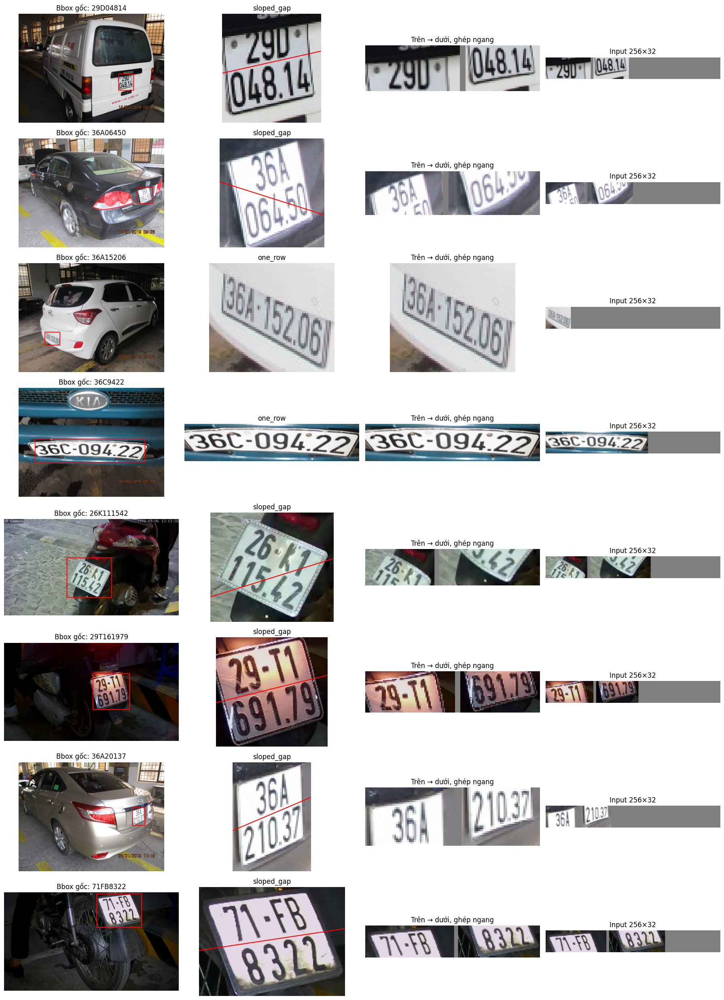

In [69]:
def subgroup_table(details,column):
    output=[]
    for value,g in details.groupby(column,dropna=False):
        output.append({column:value,**summarize(g)})
    return pd.DataFrame(output)

if RUN_FINAL_TEST:
    test_metrics,test_predictions=run_epoch(model,test_loader)
    print('TEST:',test_metrics)
    json_save(test_metrics,RUN_DIR/'test_metrics.json')
    test_predictions.to_csv(RUN_DIR/'test_predictions.csv',index=False)
    for col in ['layout','label_len','split_ok','quality_review']:
        table=subgroup_table(test_predictions,col)
        display(table)
        table.to_csv(RUN_DIR/f'test_by_{col}.csv',index=False)
else:
    print('Chưa chạy test. Sau khi chốt mô hình, bật RUN_FINAL_TEST và chạy lại cell này.')

# Phân tích lỗi validation để cải thiện; tránh dùng test để chọn kỹ thuật.
errors=val_predictions[~val_predictions.correct].sort_values('edit_distance',ascending=False)
display(errors.head(30))
error_frame=df.merge(errors[['image_id','prediction']],on='image_id')
show_pipeline(error_frame,8,seed=7)

## 8. Benchmark và inference
Benchmark model-only (không phải FPS end-to-end), cùng thiết bị, batch=1, warmup và đồng bộ GPU.
Hàm predict_plate nhận crop RGB từ YOLO hoặc GT. Với detector hiện tại, phải cung cấp layout.
Tỷ lệ w/h chỉ là heuristic; muốn tự động chọn layout tin cậy cần classifier được đánh giá riêng.
Lưu cảnh báo tách hàng cùng kết quả; đừng dùng confidence CTC như xác suất đúng toàn biển.

In [67]:
@torch.inference_mode()
def benchmark_model(model,iterations=100,warmup=20):
    model.eval()
    x=torch.zeros(1,3,HEIGHT,WIDTH,device=DEVICE)
    for _ in range(warmup): model(x)
    if DEVICE.type=='cuda': torch.cuda.synchronize()
    begin=time.perf_counter()
    for _ in range(iterations): model(x)
    if DEVICE.type=='cuda': torch.cuda.synchronize()
    latency=(time.perf_counter()-begin)/iterations
    return dict(model_ms_batch1=1000*latency,model_fps_batch1=1/latency,
                precision='FP32',parameters=sum(p.numel() for p in model.parameters()),
                device=str(DEVICE),gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None)
speed=benchmark_model(model)
print(speed); json_save(speed,RUN_DIR/'model_benchmark.json')

@torch.inference_mode()
def predict_plate(crop_rgb,layout):
    assert layout in {'one_row','two_rows'}
    crop=np.asarray(crop_rgb,dtype=np.uint8)
    assert crop.ndim==3 and crop.shape[2]==3 and min(crop.shape[:2])>1
    line=crop; split_ok=True; method='one_row'
    if layout=='two_rows':
        cut,split_ok,method,_,_=row_separator(crop)
        line=merge_rows(crop,cut)
    image,_,_=letterbox(line)
    x=torch.from_numpy(image.copy()).permute(2,0,1).unsqueeze(0).float().to(DEVICE)/127.5-1
    model.eval()
    text=greedy_decode(model(x))[0]
    return dict(text=text,layout=layout,split_ok=split_ok,split_method=method)

example=val_frame[val_frame.valid].iloc[0]
crop,_=crop_plate(read_rgb(example.path),example)
print('GT:',example.text,'Prediction:',predict_plate(crop,example.layout))
# OpenCV đọc BGR: nhớ cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB) trước predict_plate.
# Ví dụ chạy lại: tái tạo CRNN, load crnn_best.pt và cùng PREPROCESS_CONFIG/CHARSET.

{'model_ms_batch1': 4.551707360005821, 'model_fps_batch1': 219.697779516019, 'precision': 'FP32', 'parameters': 8200805, 'device': 'cuda', 'gpu': 'Tesla T4'}
GT: 36A38783 Prediction: {'text': '36A38783', 'layout': 'one_row', 'split_ok': True, 'split_method': 'one_row'}
